In [ ]:

# CELL 1: Inspect existing Python environment

import sys
import platform
import subprocess
import importlib.metadata as metadata

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Operating system:", platform.platform())

packages = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "torch",
    "transformers",
    "accelerate",
    "huggingface-hub"
]

print("\nInstalled package versions:")

for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

print("\nPip version:")
subprocess.run([sys.executable, "-m", "pip", "--version"])


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python executable: /usr/bin/python3
Operating system: Linux-6.6.159+-x86_64-with-glibc2.39

Installed package versions:
numpy: 2.4.6
pandas: 2.2.3
scipy: 1.16.3
scikit-learn: 1.6.1
matplotlib: 3.10.0
torch: 2.14.1+cu130
transformers: 5.22.1
accelerate: 1.15.0
huggingface-hub: 1.33.0

Pip version:


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', '--version'], returncode=0)

In [ ]:
%pip install "numpy>=2.0,<3" "pandas>=2.2,<3" "scipy>=1.13,<2" "scikit-learn>=1.5,<2" "matplotlib>=3.8,<4"

In [ ]:
%pip check

ipython 7.34.0 requires jedi, which is not installed.


In [ ]:

# CELL 2: Create project structure

from pathlib import Path

PROJECT = Path("/content/causal_preservation_study")

directories = [
    "data/raw",
    "data/processed",
    "data/manifests",
    "src",
    "notebooks",
    "configs",
    "scripts",
    "results/tables",
    "results/figures",
    "paper",
    "logs",
    "prompts",
    "tests"
]

for directory in directories:
    (PROJECT / directory).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT)

print("\nCreated directories:")
for path in sorted(PROJECT.rglob("*")):
    if path.is_dir():
        print(path.relative_to(PROJECT))


Project directory: /content/causal_preservation_study

Created directories:
configs
data
data/manifests
data/processed
data/raw
logs
notebooks
paper
prompts
results
results/figures
results/tables
scripts
src
tests


In [ ]:

# CELL 3: Configure reproducibility

import random
import numpy as np

SEED = 20261114

random.seed(SEED)
np.random.seed(SEED)

print("Python random seed:", SEED)
print("NumPy random seed:", SEED)

# Optional: configure PyTorch only if it is already installed.
try:
    import torch

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    print("PyTorch seed configured.")

except ImportError:
    print("PyTorch not required for the primary experiment.")


Python random seed: 20261114
NumPy random seed: 20261114
PyTorch seed configured.


In [ ]:

# CELL 4: System and GPU diagnostics

import os
import platform
import subprocess

print("Operating system:", platform.platform())
print("CPU architecture:", platform.machine())
print("CPU cores:", os.cpu_count())

print("\nGPU diagnostic:")

try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True
    )

    if result.returncode == 0:
        print(result.stdout)
    else:
        print("No NVIDIA GPU detected or nvidia-smi unavailable.")

except FileNotFoundError:
    print("nvidia-smi command is not available.")

print("\nDisk information:")

result = subprocess.run(
    ["df", "-h", "/content"],
    capture_output=True,
    text=True
)

print(result.stdout)


Operating system: Linux-6.6.159+-x86_64-with-glibc2.39
CPU architecture: x86_64
CPU cores: 2

GPU diagnostic:
Sat Nov 14 05:40:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P0             29W /   70W |     605MiB /  15360MiB |      0%      Default |
|                             

In [ ]:

# CELL 5: Final environment test
# Run after Cells 1-4.

import sys
import random
import platform

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib

from sklearn.metrics import accuracy_score

print("=" * 55)
print("CAUSAL PRESERVATION ENVIRONMENT TEST")
print("=" * 55)

# 1. Python
print("\n[1] Python")
print(sys.version)

# 2. Library versions
print("\n[2] Library versions")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

# 3. DataFrame test
print("\n[3] Pandas test")

df = pd.DataFrame({
    "claim_id": ["C001", "C002", "C003"],
    "label": ["causal", "correlational", "conditional"]
})

assert len(df) == 3
assert df["claim_id"].is_unique

print(df)
print("Pandas test: PASS")

# 4. NumPy test
print("\n[4] NumPy test")

values = np.array([1, 2, 3, 4, 5])
mean_value = np.mean(values)

assert np.isclose(mean_value, 3.0)

print("Mean:", mean_value)
print("NumPy test: PASS")

# 5. Scikit-learn test
print("\n[5] Scikit-learn test")

y_true = [0, 1, 1, 0]
y_pred = [0, 1, 0, 0]

score = accuracy_score(y_true, y_pred)

assert np.isclose(score, 0.75)

print("Accuracy:", score)
print("Scikit-learn test: PASS")

# 6. Reproducibility test
print("\n[6] Random seed test")

random.seed(20261114)
first = random.random()

random.seed(20261114)
second = random.random()

assert first == second

print("Seed reproducibility: PASS")

# 7. GPU diagnostic
print("\n[7] GPU diagnostic")

try:
    import torch

    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
    else:
        print("GPU not available; CPU is sufficient for this study.")

except ImportError:
    print("PyTorch not installed; GPU test skipped.")

# 8. Final result
print("\n" + "=" * 55)
print("ENVIRONMENT TEST COMPLETED SUCCESSFULLY")
print("=" * 55)


CAUSAL PRESERVATION ENVIRONMENT TEST

[1] Python
3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

[2] Library versions
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
Scikit-learn: 1.6.1
Matplotlib: 3.10.0

[3] Pandas test
  claim_id          label
0     C001         causal
1     C002  correlational
2     C003    conditional
Pandas test: PASS

[4] NumPy test
Mean: 3.0
NumPy test: PASS

[5] Scikit-learn test
Accuracy: 0.75
Scikit-learn test: PASS

[6] Random seed test
Seed reproducibility: PASS

[7] GPU diagnostic
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4

ENVIRONMENT TEST COMPLETED SUCCESSFULLY


In [ ]:

# MODULE 1: Download and inspect the original dataset

from pathlib import Path
import subprocess
import pandas as pd
import json

# Reproducibility: fixed repository location
PROJECT_DIR = Path("/content/causal_language_reproduction")
REPO_DIR = PROJECT_DIR / "causal-language-use-in-science"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

REPO_URL = (
    "https://github.com/junwang4/"
    "causal-language-use-in-science.git"
)

# 1. Clone the repository (only if it is not already present)
if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )
else:
    print("Repository already exists. Reusing local copy.")

# 2. Record the exact repository commit
commit = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
    text=True
).strip()

print("Repository commit:", commit)

# 3. Inspect repository files
print("\nRepository files:")
for path in sorted(REPO_DIR.rglob("*")):
    if path.is_file() and ".git" not in path.parts:
        print(path.relative_to(REPO_DIR))

# 4. Find possible tabular dataset files
data_dir = REPO_DIR / "data"

if not data_dir.exists():
    raise FileNotFoundError(
        "Expected data/ directory was not found."
    )

supported_extensions = {".csv", ".tsv", ".xlsx", ".json"}

data_files = [
    p for p in data_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in supported_extensions
]

print("\nCandidate dataset files:", len(data_files))

if not data_files:
    raise FileNotFoundError(
        "No supported tabular data files found in data/."
    )

# 5. Load and inspect each candidate without modifying it
loaded_datasets = {}

for file_path in data_files:
    print("\n" + "=" * 60)
    print("File:", file_path.name)

    suffix = file_path.suffix.lower()

    if suffix == ".csv":
        df = pd.read_csv(file_path)
    elif suffix == ".tsv":
        df = pd.read_csv(file_path, sep="\t")
    elif suffix == ".xlsx":
        df = pd.read_excel(file_path)
    elif suffix == ".json":
        df = pd.read_json(file_path)

    loaded_datasets[file_path.name] = df

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst five rows:")
    print(df.head())

    print("\nData types:")
    print(df.dtypes)

# 6. Basic acquisition sanity tests
assert REPO_DIR.exists(), "Repository directory is missing."
assert len(data_files) > 0, "No dataset files were discovered."
assert len(loaded_datasets) > 0, "No dataset was loaded."

print("\nMODULE 1 ACQUISITION TEST PASSED")


Repository already exists. Reusing local copy.
Repository commit: 84abecc88b201a5ce27e1622597f780a9800c498

Repository files:
.gitignore
LICENSE
README.md
data/pubmed_causal_language_use.csv
data/sample_new_sentences.csv
main.py

Candidate dataset files: 2

File: sample_new_sentences.csv
Shape: (100, 2)
Columns: ['pmid', 'sentence']

First five rows:
       pmid                                           sentence
0  31064345  Five hundred twenty-five patients were include...
1  31064345  During follow-up 11.1-24.0% of patients had a ...
2  31064345  21.4-50.8% of employed patients took sick leav...
3  31064345  The mean annual direct cost to the healthcare ...
4  31064345  The total direct cost (combined costs to healt...

Data types:
pmid         int64
sentence    object
dtype: object

File: pubmed_causal_language_use.csv
Shape: (3061, 2)
Columns: ['sentence', 'label']

First five rows:
                                            sentence  label
0  Levels of cholesterol fractions in pa

In [ ]:

# MODULE 2: Dataset validation and integrity checks

from pathlib import Path
import pandas as pd
import hashlib
import json

# Dataset location from Module 1
PROJECT_DIR = Path("/content/causal_language_reproduction")
DATA_FILE = (
    PROJECT_DIR
    / "causal-language-use-in-science"
    / "data"
    / "pubmed_causal_language_use.csv"
)

assert DATA_FILE.exists(), f"Dataset not found: {DATA_FILE}"

# 1. Load the original dataset
df = pd.read_csv(DATA_FILE)

# 2. Validate schema
expected_columns = ["sentence", "label"]

assert list(df.columns) == expected_columns, (
    f"Unexpected columns: {df.columns.tolist()}"
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# 3. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Check data types
print("\nData types:")
print(df.dtypes)

# 5. Check labels and class distribution
expected_counts = {
    0: 1356,
    1: 494,
    2: 213,
    3: 998
}

observed_counts = df["label"].value_counts().sort_index()

print("\nObserved class distribution:")
print(observed_counts)

print("\nExpected class distribution:")
print(pd.Series(expected_counts).sort_index())

# 6. Check invalid labels
valid_labels = set(expected_counts.keys())
observed_labels = set(df["label"].dropna().unique())

invalid_labels = observed_labels - valid_labels

print("\nInvalid labels:", invalid_labels)

# 7. Check duplicate sentences
duplicate_count = df["sentence"].duplicated().sum()

print("\nExact duplicate sentences:", duplicate_count)

# 8. Check empty or whitespace-only sentences
empty_count = (
    df["sentence"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

print("Empty/whitespace-only sentences:", empty_count)

# 9. Check suspicious encoding markers
suspicious_pattern = r"Ã|Â|Î|�"

suspicious_mask = (
    df["sentence"]
    .fillna("")
    .str.contains(suspicious_pattern, regex=True)
)

print("\nSentences with suspicious encoding markers:",
      suspicious_mask.sum())

if suspicious_mask.any():
    print("\nExamples requiring manual inspection:")
    print(df.loc[suspicious_mask, "sentence"].head(5).to_string(index=False))

# 10. Verify total rows and class counts
assert len(df) == 3061, (
    f"Expected 3061 rows, found {len(df)}"
)

assert observed_labels == valid_labels, (
    f"Unexpected label set: {observed_labels}"
)

assert observed_counts.to_dict() == expected_counts, (
    "Class counts do not match the expected published distribution."
)

assert df["sentence"].notna().all(), "Missing sentences detected."
assert df["label"].notna().all(), "Missing labels detected."
assert empty_count == 0, "Empty sentences detected."

# 11. Calculate SHA-256 hash for dataset provenance
file_hash = hashlib.sha256(
    DATA_FILE.read_bytes()
).hexdigest()

# 12. Save validation report
manifest = {
    "dataset": DATA_FILE.name,
    "repository_commit": "84abecc88b201a5ce27e1622597f780a9800c498",
    "rows": int(df.shape[0]),
    "columns": df.columns.tolist(),
    "class_counts": {
        str(k): int(v)
        for k, v in observed_counts.items()
    },
    "duplicate_sentences": int(duplicate_count),
    "empty_sentences": int(empty_count),
    "suspicious_encoding_rows": int(suspicious_mask.sum()),
    "sha256": file_hash
}

manifest_dir = PROJECT_DIR / "data" / "manifests"
manifest_dir.mkdir(parents=True, exist_ok=True)

manifest_path = manifest_dir / "dataset_validation.json"

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=4)

print("\nDataset SHA-256:", file_hash)
print("Validation report saved:", manifest_path)

print("\nMODULE 2 VALIDATION TEST PASSED")


Dataset shape: (3061, 2)
Columns: ['sentence', 'label']

Missing values:
sentence    0
label       0
dtype: int64

Data types:
sentence    object
label        int64
dtype: object

Observed class distribution:
label
0    1356
1     494
2     213
3     998
Name: count, dtype: int64

Expected class distribution:
0    1356
1     494
2     213
3     998
dtype: int64

Invalid labels: set()

Exact duplicate sentences: 7
Empty/whitespace-only sentences: 0

Sentences with suspicious encoding markers: 32

Examples requiring manual inspection:
PPARÎ´ peroxisome proliferator-activated recept...
Graphical abstract Summary of the mechanism of ...
Our data indicate the iodine requirement in 2- ...
Cancer 2017;123:948-56.Â© 2016 American Cancer ...
Cancer 2017;123:210-218.Â© 2016 American Cancer...

Dataset SHA-256: f3e50fb07bfe9c9dcbbe3bbfcf0a27e71d460e06895b2867002a61c34ee1f202
Validation report saved: /content/causal_language_reproduction/data/manifests/dataset_validation.json

MODULE 2 VALIDATION 

In [ ]:

# MODULE 2A: Duplicate and encoding inspection

import pandas as pd
from pathlib import Path

data_path = Path(
    "/content/causal_language_reproduction/"
    "causal-language-use-in-science/data/"
    "pubmed_causal_language_use.csv"
)

df = pd.read_csv(data_path)

# 1. Inspect all rows belonging to duplicate groups
duplicates = df[
    df.duplicated(subset=["sentence"], keep=False)
].copy()

duplicates["original_row"] = duplicates.index

print("=== DUPLICATE ANALYSIS ===")
print("Rows in duplicate groups:", len(duplicates))
print("Extra duplicate rows:", df["sentence"].duplicated().sum())
print("Distinct repeated sentences:",
      duplicates["sentence"].nunique())

# 2. Detect conflicting labels for identical sentences
conflicts = (
    duplicates.groupby("sentence")["label"]
    .nunique()
)

conflicting_sentences = conflicts[conflicts > 1]

print("Sentences with conflicting labels:",
      len(conflicting_sentences))

# Display each duplicate group, preserving original row IDs
for sentence, group in duplicates.groupby("sentence", sort=False):
    print("\nSentence:", repr(sentence[:250]))
    print("Row IDs:", group["original_row"].tolist())
    print("Labels:", group["label"].tolist())

# 3. Inspect suspicious encoding
print("\n=== ENCODING INSPECTION ===")

pattern = r"Ã|Â|Î|�"

suspect = df[
    df["sentence"].str.contains(pattern, regex=True, na=False)
]

print("Flagged sentences:", len(suspect))

for idx, row in suspect.head(10).iterrows():
    print(f"\nRow {idx}, label {row['label']}")
    print(repr(row["sentence"][:300]))

# 4. Basic sanity checks
assert len(df) == 3061
assert df["label"].isin([0, 1, 2, 3]).all()
assert df["sentence"].notna().all()

print("\nMODULE 2A INSPECTION COMPLETED")


=== DUPLICATE ANALYSIS ===
Rows in duplicate groups: 14
Extra duplicate rows: 7
Distinct repeated sentences: 7
Sentences with conflicting labels: 1

Sentence: 'CLINICAL TRIAL REGISTRATION: URL: https://www.clinicaltrials.gov.'
Row IDs: [112, 1270]
Labels: [0, 0]

Sentence: 'CLINICAL QUESTION/LEVEL OF EVIDENCE: Therapeutic, II.'
Row IDs: [114, 963]
Labels: [0, 0]

Sentence: 'None the less, both artificially sweetened beverages and fruit juice were unlikely to be healthy alternatives to sugar sweetened beverages for the prevention of type 2 diabetes.'
Row IDs: [223, 1864]
Labels: [0, 2]

Sentence: 'TRIAL REGISTRATION: Not applicable.'
Row IDs: [376, 1236]
Labels: [0, 0]

Sentence: 'Habitual consumption of sugar sweetened beverages was associated with a greater incidence of type 2 diabetes, independently of adiposity.'
Row IDs: [2356, 2457]
Labels: [3, 3]

Sentence: 'Although artificially sweetened beverages and fruit juice also showed positive associations with incidence of type 2 diabet

In [ ]:

# MODULE 3A: Inspect the official baseline implementation
# No preprocessing or training is performed.

from pathlib import Path
import subprocess

repo = Path(
    "/content/causal_language_reproduction/"
    "causal-language-use-in-science"
)

assert (repo / "main.py").is_file()
assert (repo / "README.md").is_file()

print("=== REPOSITORY COMMIT ===")
print(subprocess.check_output(
    ["git", "-C", str(repo), "rev-parse", "HEAD"],
    text=True
).strip())

for filename in ["README.md", "main.py"]:
    path = repo / filename
    print(f"\n{'=' * 25} {filename} {'=' * 25}")

    lines = path.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    print(f"Total lines: {len(lines)}")

    for line_number, line in enumerate(lines, start=1):
        print(f"{line_number:04d}: {line}")

print("\nMODULE 3A SOURCE INSPECTION COMPLETED")


=== REPOSITORY COMMIT ===
84abecc88b201a5ce27e1622597f780a9800c498

========================= README.md =========================
Total lines: 59
0001: # Detecting Causal Language Use in Science Findings
0002: 
0003: This is a collaborative project with the School of Information at Syracuse University. The goal of the project is to develop an automated NLP model that can identify causal language use in science findings, and to further study whether causal language use differs by countries and languages. We have developed an annotated corpus and trained a BioBert model with 0.88 macro-F1 score to categorize conclusion sentences into direct causal, conditional causal, correlational, and no relationships. We then applied this model to the observational studies in PubMed, and observed different levels of causal language use by authors from different countries and language backgrounds. This result challenges the notion of a shared consensus on causal language use in global science community

In [ ]:

# MODULE 3B: Validate the official cross-validation protocol
# No training, model loading, or dataset modifications.

from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight

DATA_FILE = Path(
    "/content/causal_language_reproduction/"
    "causal-language-use-in-science/data/"
    "pubmed_causal_language_use.csv"
)

df = pd.read_csv(
    DATA_FILE,
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)

# Match official clean_str()
df["sentence"] = df["sentence"].apply(lambda s: s.strip())

K = 5
RANDOM_STATE = 0

skf = StratifiedKFold(
    n_splits=K,
    shuffle=True,
    random_state=RANDOM_STATE
)

folds = list(skf.split(df["sentence"], df["label"]))

print("scikit-learn version:", sklearn.__version__)
print("Dataset shape:", df.shape)
print("Number of folds:", len(folds))

seen_test_indices = []
fold_sizes = []

print("\n=== FOLD DETAILS ===")

for fold, (train_idx, test_idx) in enumerate(folds):
    train_df = df.iloc[train_idx]
    test_df = df.iloc[test_idx]

    # Train/test overlap in row indices is prohibited
    overlap = set(train_idx) & set(test_idx)
    assert len(overlap) == 0

    # The official implementation uses full-data weights
    classes = np.array([0, 1, 2, 3])

    full_weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=df["label"].to_numpy()
    )

    train_weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=train_df["label"].to_numpy()
    )

    # Count exact sentence overlap across the split
    repeated_text = (
        set(train_df["sentence"])
        & set(test_df["sentence"])
    )

    print(f"\nFold {fold}")
    print("  Train rows:", len(train_df))
    print("  Test rows:", len(test_df))
    print("  Test class counts:",
          test_df["label"].value_counts().sort_index().to_dict())
    print("  Overlapping row indices:", len(overlap))
    print("  Overlapping sentence strings:", len(repeated_text))
    print("  Full-data class weights:",
          np.round(full_weights, 6).tolist())
    print("  Train-only class weights:",
          np.round(train_weights, 6).tolist())

    seen_test_indices.extend(test_idx.tolist())
    fold_sizes.append(len(test_idx))

# Every original row must appear once in a test fold
assert len(seen_test_indices) == len(df)
assert len(set(seen_test_indices)) == len(df)
assert set(seen_test_indices) == set(range(len(df)))

# Repeated construction must yield identical indices
folds_again = list(
    StratifiedKFold(
        n_splits=K,
        shuffle=True,
        random_state=RANDOM_STATE
    ).split(df["sentence"], df["label"])
)

assert all(
    np.array_equal(a[0], b[0])
    and np.array_equal(a[1], b[1])
    for a, b in zip(folds, folds_again)
)

print("\n=== SUMMARY ===")
print("Observed fold sizes:", fold_sizes)
print("README fold sizes:", [614, 613, 613, 611, 610])
print("Fold sizes match README:",
      fold_sizes == [614, 613, 613, 611, 610])

print("All rows tested exactly once: True")
print("Deterministic split construction: True")
print("\nMODULE 3B SPLIT SANITY TEST PASSED")


scikit-learn version: 1.6.1
Dataset shape: (3061, 2)
Number of folds: 5

=== FOLD DETAILS ===

Fold 0
  Train rows: 2448
  Test rows: 613
  Test class counts: {0: 272, 1: 98, 2: 43, 3: 200}
  Overlapping row indices: 0
  Overlapping sentence strings: 2
  Full-data class weights: [0.564344, 1.549089, 3.592723, 0.766784]
  Train-only class weights: [0.564576, 1.545455, 3.6, 0.766917]

Fold 1
  Train rows: 2449
  Test rows: 612
  Test class counts: {0: 271, 1: 99, 2: 43, 3: 199}
  Overlapping row indices: 0
  Overlapping sentence strings: 3
  Full-data class weights: [0.564344, 1.549089, 3.592723, 0.766784]
  Train-only class weights: [0.564286, 1.55, 3.601471, 0.76627]

Fold 2
  Train rows: 2449
  Test rows: 612
  Test class counts: {0: 271, 1: 99, 2: 43, 3: 199}
  Overlapping row indices: 0
  Overlapping sentence strings: 4
  Full-data class weights: [0.564344, 1.549089, 3.592723, 0.766784]
  Train-only class weights: [0.564286, 1.55, 3.601471, 0.76627]

Fold 3
  Train rows: 2449
  Test

In [ ]:

from pathlib import Path
import subprocess
import sys

PROJECT_DIR = Path("/content/causal_language_reproduction")
DEPENDENCY_DIR = PROJECT_DIR / "bert-sklearn-with-class-weight"

URL = "https://github.com/junwang4/bert-sklearn-with-class-weight.git"

if not DEPENDENCY_DIR.exists():
    subprocess.run(
        ["git", "clone", URL, str(DEPENDENCY_DIR)],
        check=True
    )

commit = subprocess.check_output(
    ["git", "-C", str(DEPENDENCY_DIR), "rev-parse", "HEAD"],
    text=True
).strip()

print("=== DEPENDENCY PROVENANCE ===")
print("Commit:", commit)
print("Python:", sys.version.split()[0])

print("\n=== REPOSITORY FILES ===")
for path in sorted(DEPENDENCY_DIR.rglob("*")):
    if path.is_file() and ".git" not in path.parts:
        print(path.relative_to(DEPENDENCY_DIR))

print("\n=== DEPENDENCY DECLARATIONS ===")
setup_file = DEPENDENCY_DIR / "setup.py"

assert setup_file.exists(), "setup.py not found"

print(setup_file.read_text(
    encoding="utf-8", errors="replace"
))

print("\n=== RELEVANT SOURCE LOCATIONS ===")

keywords = [
    "biobert-base-cased",
    "class_weight",
    "max_seq_length",
    "validation_fraction",
    "learning_rate",
    "warmup",
    "Adam",
    "CrossEntropyLoss",
    "random_state",
    "tokenizer",
]

matches = 0

for file in sorted(DEPENDENCY_DIR.rglob("*.py")):
    lines = file.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for number, line in enumerate(lines, start=1):
        if any(word.lower() in line.lower() for word in keywords):
            matches += 1
            print(
                f"{file.relative_to(DEPENDENCY_DIR)}:"
                f"{number}: {line[:220]}"
            )

print("\nSource matches:", matches)
assert matches > 0, "No relevant source references found"

print("\nMODULE 3C SOURCE INSPECTION COMPLETED")


=== DEPENDENCY PROVENANCE ===
Commit: 5f63b4c3ec3f3c4c06a73713a57f7a5f9354ae10
Python: 3.13.16

=== REPOSITORY FILES ===
.gitignore
README.md
bert_sklearn/__init__.py
bert_sklearn/config.py
bert_sklearn/data/__init__.py
bert_sklearn/data/data.py
bert_sklearn/data/utils.py
bert_sklearn/finetune.py
bert_sklearn/model/__init__.py
bert_sklearn/model/model.py
bert_sklearn/model/pytorch_pretrained/__init__.py
bert_sklearn/model/pytorch_pretrained/file_utils.py
bert_sklearn/model/pytorch_pretrained/modeling.py
bert_sklearn/model/pytorch_pretrained/optimization.py
bert_sklearn/model/pytorch_pretrained/tokenization.py
bert_sklearn/model/utils.py
bert_sklearn/sklearn.py
bert_sklearn/utils.py
setup.py

=== DEPENDENCY DECLARATIONS ===
from setuptools import find_packages, setup

setup(
    name="bert_sklearn",
    version="0.3.1",
    author="charles_nainan",
    author_email="charles.j.9n@gmail.com",
    description="A sklearn wrapper for Bert",
    keywords='scikit sklearn BERT sklearn NLP deep 

In [ ]:

from pathlib import Path

ROOT = Path(
    "/content/causal_language_reproduction/"
    "bert-sklearn-with-class-weight"
)

sections = {
    "bert_sklearn/sklearn.py": [
        (150, 205),
        (315, 405),
    ],
    "bert_sklearn/config.py": [
        (65, 105),
    ],
    "bert_sklearn/finetune.py": [
        (35, 155),
    ],
    "bert_sklearn/utils.py": [
        (135, 215),
    ],
    "bert_sklearn/model/utils.py": [
        (45, 115),
    ],
    "bert_sklearn/model/model.py": [
        (55, 125),
    ],
}

for filename, ranges in sections.items():
    path = ROOT / filename
    assert path.is_file(), f"Missing source: {filename}"

    lines = path.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    print(f"\n{'=' * 65}")
    print(filename)

    for start, end in ranges:
        print(f"\n--- Lines {start}-{end} ---")

        for index in range(start - 1, min(end, len(lines))):
            print(f"{index + 1:04d}: {lines[index]}")

print("\nMODULE 3D DEFAULTS INSPECTION COMPLETED")



bert_sklearn/sklearn.py

--- Lines 150-205 ---
0150:                  bert_config_json=None, bert_vocab=None,
0151:                  from_tf=False, do_lower_case=None, label_list=None,
0152:                  num_mlp_hiddens=500, num_mlp_layers=0, restore_file=None,
0153:                  epochs=3, max_seq_length=128, train_batch_size=32,
0154:                  eval_batch_size=8, learning_rate=2e-5, warmup_proportion=0.1,
0155:                  gradient_accumulation_steps=1, fp16=False, loss_scale=0,
0156:                  local_rank=-1, use_cuda=True, random_state=42,
0157:                  validation_fraction=0.1, logfile='tmp_bert_sklearn.log',
0158:                  class_weight=None,
0159:                  ignore_label=None):
0160: 
0161:         self.id2label, self.label2id = {}, {}
0162:         self.input_text_pairs = None
0163: 
0164:         self.bert_model = bert_model
0165:         self.bert_config_json = bert_config_json
0166:         self.bert_vocab = bert_vocab
0167:    

In [ ]:

from pathlib import Path
import ast

ROOT = Path(
    "/content/causal_language_reproduction/"
    "bert-sklearn-with-class-weight"
)

targets = {
    "bert_sklearn/utils.py": ["set_random_seed"],
    "bert_sklearn/data/data.py": ["get_train_val_dl"],
    "bert_sklearn/sklearn.py": ["load_tokenizer"],
}

for filename, function_names in targets.items():
    path = ROOT / filename
    source = path.read_text(encoding="utf-8")
    tree = ast.parse(source)
    lines = source.splitlines()

    print(f"\n{'=' * 50}")
    print(filename)

    for node in ast.walk(tree):
        if isinstance(node, ast.FunctionDef):
            if node.name in function_names:
                print(f"\nFUNCTION: {node.name}")
                for i in range(node.lineno - 1, node.end_lineno):
                    print(f"{i+1:04d}: {lines[i]}")

print("\nMODULE 3E INSPECTION COMPLETED")



bert_sklearn/utils.py

FUNCTION: set_random_seed
0010: def set_random_seed(seed=42, use_cuda=True):
0011:     """Seed all random number generators to enable repeatable runs"""
0012:     random.seed(seed)
0013:     np.random.seed(seed)
0014:     torch.manual_seed(seed)
0015:     if use_cuda:
0016:         torch.cuda.manual_seed_all(seed)

bert_sklearn/data/data.py

FUNCTION: get_train_val_dl
0232: def get_train_val_dl(X1, X2, y, config):
0233:     """
0234:     Get train and validation dataloaders.
0235: 
0236:     Parameters
0237:     ----------
0238:     X1 : list of strings
0239:         text_a for input data pairs for text classification/regression
0240:         OR
0241:         list of list of strings
0242:         for sequence/token tasks
0243: 
0244:     X2 : list of strings
0245:         text_b for input data text pairs for text classification/regression
0246: 
0247:     y : list of string or list of floats
0248:         labels/targets for data
0249: 
0250:     config : Finetun

In [ ]:

# MODULE 4A: Runtime compatibility preflight
# Read-only: no installation or model download

import sys
import platform
import importlib
import importlib.metadata as metadata
import subprocess

packages = {
    "torch": "torch",
    "transformers": "transformers",
    "huggingface_hub": "huggingface-hub",
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "safetensors": "safetensors",
}

print("=== PYTHON ENVIRONMENT ===")
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())

print("\n=== PACKAGE VERSIONS ===")

for module_name, package_name in packages.items():
    try:
        version = metadata.version(package_name)
        print(f"{package_name}: {version}")
    except metadata.PackageNotFoundError:
        print(f"{package_name}: NOT INSTALLED")

print("\n=== PYTORCH / CUDA ===")

try:
    import torch

    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("CUDA version:", torch.version.cuda)

        x = torch.tensor([1.0, 2.0, 3.0], device="cuda")
        print("GPU tensor sanity test:", x.sum().item())

        assert x.sum().item() == 6.0

except Exception as exc:
    print("PyTorch diagnostic error:", repr(exc))

print("\n=== TRANSFORMERS IMPORT ===")

try:
    from transformers import BertConfig, BertModel, BertTokenizer

    print("BertConfig: IMPORT SUCCESS")
    print("BertModel: IMPORT SUCCESS")
    print("BertTokenizer: IMPORT SUCCESS")

except Exception as exc:
    print("Transformers import error:", repr(exc))

print("\n=== PACKAGE CONSISTENCY ===")

result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print("pip check return code:", result.returncode)
print((result.stdout + result.stderr)[:4000])

print("\nMODULE 4A DIAGNOSTICS COMPLETED")


=== PYTHON ENVIRONMENT ===
Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

=== PACKAGE VERSIONS ===
torch: 2.14.1+cu130
transformers: 5.22.1
huggingface-hub: 1.33.0
numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
safetensors: 0.8.0

=== PYTORCH / CUDA ===
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0
GPU tensor sanity test: 6.0

=== TRANSFORMERS IMPORT ===
BertConfig: IMPORT SUCCESS
BertModel: IMPORT SUCCESS
BertTokenizer: IMPORT SUCCESS

=== PACKAGE CONSISTENCY ===
pip check return code: 1
ipython 7.34.0 requires jedi, which is not installed.


MODULE 4A DIAGNOSTICS COMPLETED


In [ ]:

# MODULE 4B: BERT architecture compatibility smoke test
# No pretrained checkpoint download or model training

import torch
import torch.nn as nn
from transformers import BertConfig, BertModel

torch.manual_seed(0)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Tiny configuration: for compatibility testing ONLY
config = BertConfig(
    vocab_size=1000,
    hidden_size=64,
    num_hidden_layers=2,
    num_attention_heads=4,
    intermediate_size=128,
    max_position_embeddings=128,
    hidden_dropout_prob=0.1
)

class TinyBertClassifier(nn.Module):
    def __init__(self, config, num_labels=4):
        super().__init__()

        self.bert = BertModel(config)
        self.dropout = nn.Dropout(
            config.hidden_dropout_prob
        )
        self.classifier = nn.Linear(
            config.hidden_size, num_labels
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        pooled = outputs.pooler_output
        logits = self.classifier(
            self.dropout(pooled)
        )

        return logits

model = TinyBertClassifier(config).to(device)
model.eval()

# Two synthetic sentences, each with 16 token IDs
input_ids = torch.randint(
    low=5,
    high=1000,
    size=(2, 16),
    device=device
)

attention_mask = torch.ones_like(input_ids)

labels = torch.tensor(
    [0, 2],
    dtype=torch.long,
    device=device
)

# Reference class weights from your validated dataset
class_weights = torch.tensor(
    [0.564344, 1.549089, 3.592723, 0.766784],
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    logits = model(input_ids, attention_mask)

    individual_losses = nn.functional.cross_entropy(
        logits,
        labels,
        weight=class_weights,
        reduction="none"
    )

    loss = individual_losses.mean()

    probabilities = torch.softmax(logits, dim=-1)

print("=== MODULE 4B ===")
print("Device:", device)
print("Input shape:", tuple(input_ids.shape))
print("Attention mask shape:", tuple(attention_mask.shape))
print("Logits shape:", tuple(logits.shape))
print("Probabilities shape:", tuple(probabilities.shape))
print("Per-example losses shape:",
      tuple(individual_losses.shape))
print("Mean weighted loss:", float(loss.item()))
print("Probability row sums:",
      probabilities.sum(dim=1).tolist())

# Unit / sanity assertions
assert logits.shape == (2, 4)
assert probabilities.shape == (2, 4)
assert individual_losses.shape == (2,)
assert torch.isfinite(logits).all()
assert torch.isfinite(loss)
assert torch.allclose(
    probabilities.sum(dim=1),
    torch.ones(2, device=device),
    atol=1e-5
)

print("\nMODULE 4B FORWARD PASS TEST PASSED")


=== MODULE 4B ===
Device: cuda
Input shape: (2, 16)
Attention mask shape: (2, 16)
Logits shape: (2, 4)
Probabilities shape: (2, 4)
Per-example losses shape: (2,)
Mean weighted loss: 2.781195878982544
Probability row sums: [0.9999999403953552, 1.0]

MODULE 4B FORWARD PASS TEST PASSED


In [ ]:

# MODULE 4C: BioBERT checkpoint metadata and tokenizer test

from pathlib import Path
import hashlib
import json
from huggingface_hub import hf_hub_download, list_repo_files
from transformers import BertConfig, BertTokenizer

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"

print("=== CHECKPOINT FILES ===")
files = list_repo_files(MODEL_ID)
for name in files:
    print(name)

print("\n=== DOWNLOAD SMALL METADATA FILES ===")
config_path = hf_hub_download(
    repo_id=MODEL_ID,
    filename="config.json"
)

vocab_path = hf_hub_download(
    repo_id=MODEL_ID,
    filename="vocab.txt"
)

config = BertConfig.from_json_file(config_path)

print("\n=== BIOBERT CONFIGURATION ===")
print("Hidden size:", config.hidden_size)
print("Encoder layers:", config.num_hidden_layers)
print("Attention heads:", config.num_attention_heads)
print("Vocabulary size:", config.vocab_size)
print("Dropout:", config.hidden_dropout_prob)
print("Max positions:", config.max_position_embeddings)

print("\n=== TOKENIZER TEST ===")
tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    do_lower_case=False
)

sentences = [
    "Smoking may increase the risk of lung cancer.",
    "Treatment was associated with improved survival."
]

encoded = tokenizer(
    sentences,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Tokenizer vocabulary:", tokenizer.vocab_size)
print("Input IDs shape:", tuple(encoded["input_ids"].shape))
print("Attention mask shape:",
      tuple(encoded["attention_mask"].shape))
print("First sentence tokens:",
      tokenizer.tokenize(sentences[0]))

vocab_hash = hashlib.sha256(
    Path(vocab_path).read_bytes()
).hexdigest()

print("Vocabulary SHA-256:", vocab_hash)

# Sanity checks
assert config.hidden_size == 768
assert config.num_hidden_layers == 12
assert config.num_attention_heads == 12
assert tokenizer.vocab_size == config.vocab_size
assert encoded["input_ids"].shape == (2, 128)
assert encoded["attention_mask"].shape == (2, 128)

print("\nMODULE 4C TOKENIZER TEST PASSED")


=== CHECKPOINT FILES ===
.gitattributes
config.json
pytorch_model.bin
vocab.txt

=== DOWNLOAD SMALL METADATA FILES ===

=== BIOBERT CONFIGURATION ===
Hidden size: 768
Encoder layers: 12
Attention heads: 12
Vocabulary size: 28996
Dropout: 0.1
Max positions: 512

=== TOKENIZER TEST ===
Tokenizer vocabulary: 28996
Input IDs shape: (2, 128)
Attention mask shape: (2, 128)
First sentence tokens: ['S', '##mo', '##king', 'may', 'increase', 'the', 'risk', 'of', 'lung', 'cancer', '.']
Vocabulary SHA-256: eeaa9875b23b04b4c54ef759d03db9d1ba1554838f8fb26c5d96fa551df93d02

MODULE 4C TOKENIZER TEST PASSED


In [ ]:

# MODULE 4D: BioBERT pretrained encoder loading test
# No training. No package installation.

import hashlib
from pathlib import Path

import torch
from huggingface_hub import hf_hub_download
from transformers import BertModel, BertTokenizer

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=== PRETRAINED CHECKPOINT ===")

weights_path = hf_hub_download(
    repo_id=MODEL_ID,
    filename="pytorch_model.bin",
    revision=REVISION
)

checkpoint_size = Path(weights_path).stat().st_size
print("Checkpoint bytes:", checkpoint_size)

# Load weights through the Transformers checkpoint loader.
# Request diagnostics for unmatched or newly initialized tensors.
model, loading_info = BertModel.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    use_safetensors=False,
    output_loading_info=True
)

print("Missing keys:", loading_info.get("missing_keys", []))
print("Unexpected keys:", loading_info.get("unexpected_keys", []))
print("Mismatched keys:", loading_info.get("mismatched_keys", []))
print("Loading errors:", loading_info.get("error_msgs", []))

model = model.to(device)
model.eval()

tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

sentences = [
    "Smoking may increase the risk of lung cancer.",
    "Treatment was associated with improved survival."
]

encoded = tokenizer(
    sentences,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

encoded = {
    key: value.to(device)
    for key, value in encoded.items()
}

with torch.inference_mode():
    outputs = model(**encoded)

print("\n=== FORWARD PASS ===")
print("Device:", device)
print("Input IDs:", tuple(encoded["input_ids"].shape))
print("Last hidden state:",
      tuple(outputs.last_hidden_state.shape))
print("Pooled output:",
      tuple(outputs.pooler_output.shape))

assert outputs.last_hidden_state.shape == (2, 128, 768)
assert outputs.pooler_output.shape == (2, 768)
assert torch.isfinite(outputs.last_hidden_state).all()
assert torch.isfinite(outputs.pooler_output).all()

# Missing keys may indicate weights initialized without
# corresponding checkpoint tensors; review before proceeding.
assert not loading_info.get("error_msgs", [])
assert not loading_info.get("mismatched_keys", [])

print("\nMODULE 4D BIOBERT FORWARD PASS PASSED")


=== PRETRAINED CHECKPOINT ===
Checkpoint bytes: 435780550


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Missing keys: set()
Unexpected keys: {'cls.predictions.decoder.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.seq_relationship.bias', 'cls.predictions.bias', 'cls.predictions.decoder.weight', 'cls.seq_relationship.weight'}
Mismatched keys: set()
Loading errors: []

=== FORWARD PASS ===
Device: cuda
Input IDs: (2, 128)
Last hidden state: (2, 128, 768)
Pooled output: (2, 768)

MODULE 4D BIOBERT FORWARD PASS PASSED


In [ ]:

# MODULE 4D-B: Minimal real BioBERT forward-pass verification
# Uses the already-loaded model and tokenizer.

import torch

assert "model" in globals(), "Model not loaded in this runtime"
assert "tokenizer" in globals(), "Tokenizer unavailable"

model.eval()

text = ["Smoking may increase the risk of lung cancer."]

batch = tokenizer(
    text,
    padding="max_length",
    truncation=True,
    max_length=16,
    return_tensors="pt"
)

batch = {
    k: v.to(device)
    for k, v in batch.items()
}

with torch.inference_mode():
    outputs = model(**batch)

print("Input shape:", tuple(batch["input_ids"].shape))
print("Hidden state shape:",
      tuple(outputs.last_hidden_state.shape))
print("Pooled output shape:",
      tuple(outputs.pooler_output.shape))

assert outputs.last_hidden_state.shape == (1, 16, 768)
assert outputs.pooler_output.shape == (1, 768)
assert torch.isfinite(outputs.last_hidden_state).all()
assert torch.isfinite(outputs.pooler_output).all()

print("MODULE 4D BIOBERT FORWARD PASS PASSED")


Input shape: (1, 16)
Hidden state shape: (1, 16, 768)
Pooled output shape: (1, 768)
MODULE 4D BIOBERT FORWARD PASS PASSED


In [ ]:

# MODULE 4E: Four-class BioBERT classifier sanity test
# No model training, optimizer steps, or dataset changes.

import torch
import torch.nn as nn
import torch.nn.functional as F

assert "model" in globals(), "Run Module 4D first."
assert "tokenizer" in globals(), "Tokenizer not available."

device = next(model.parameters()).device

# Exact source-dataset class counts
counts = torch.tensor(
    [1356, 494, 213, 998],
    dtype=torch.float32,
    device=device
)

num_labels = 4
class_weights = counts.sum() / (num_labels * counts)

# Match the inspected reference architecture
class BioBertFourClassClassifier(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.bert = encoder
        self.dropout = nn.Dropout(
            encoder.config.hidden_dropout_prob
        )
        self.classifier = nn.Linear(
            encoder.config.hidden_size,
            num_labels
        )

    def forward(self, input_ids, attention_mask, token_type_ids=None):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        pooled = outputs.pooler_output
        return self.classifier(self.dropout(pooled))

# Reproducible initialization of the new classification head
torch.manual_seed(0)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(0)

classifier = BioBertFourClassClassifier(model).to(device)
classifier.eval()

sentences = [
    "Smoking may increase the risk of lung cancer.",
    "Treatment was associated with improved survival."
]
labels = torch.tensor([1, 3], dtype=torch.long, device=device)

batch = tokenizer(
    sentences,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)
batch = {k: v.to(device) for k, v in batch.items()}

# Reference loss: unreduced class-weighted CE,
# followed by arithmetic mean over examples
with torch.inference_mode():
    logits = classifier(**batch)
    per_example_loss = F.cross_entropy(
        logits,
        labels,
        weight=class_weights,
        reduction="none"
    )
    loss = per_example_loss.mean()
    probabilities = torch.softmax(logits, dim=-1)

print("=== FOUR-CLASS CLASSIFIER TEST ===")
print("Device:", device)
print("Input shape:", tuple(batch["input_ids"].shape))
print("Pooled dimension:", model.config.hidden_size)
print("Logits shape:", tuple(logits.shape))
print("Probabilities shape:", tuple(probabilities.shape))
print("Class weights:", class_weights.tolist())
print("Per-example loss:", per_example_loss.tolist())
print("Mean loss:", loss.item())
print("Probability sums:", probabilities.sum(dim=-1).tolist())

# Unit/sanity tests
assert logits.shape == (2, 4)
assert probabilities.shape == (2, 4)
assert per_example_loss.shape == (2,)
assert loss.ndim == 0
assert torch.isfinite(logits).all()
assert torch.isfinite(loss)
assert torch.allclose(
    probabilities.sum(dim=-1),
    torch.ones(2, device=device),
    atol=1e-5
)

# Validate exact loss-reduction behavior
manual_loss = (
    -class_weights[labels]
    * torch.log_softmax(logits, dim=-1)
      .gather(1, labels.unsqueeze(1)).squeeze(1)
).mean()

assert torch.allclose(loss, manual_loss, atol=1e-6)

print("\nMODULE 4E CLASSIFIER SANITY TEST PASSED")


=== FOUR-CLASS CLASSIFIER TEST ===
Device: cuda:0
Input shape: (2, 128)
Pooled dimension: 768
Logits shape: (2, 4)
Probabilities shape: (2, 4)
Class weights: [0.5643436312675476, 1.5490890741348267, 3.5927228927612305, 0.766783595085144]
Per-example loss: [1.5473510026931763, 1.2712887525558472]
Mean loss: 1.4093198776245117
Probability sums: [1.0, 1.0000001192092896]

MODULE 4E CLASSIFIER SANITY TEST PASSED


In [ ]:

# MODULE 4F: Inspect the exact historical MLP architecture
# Read-only source inspection; no GPU execution

from pathlib import Path
import ast

ROOT = Path(
    "/content/causal_language_reproduction/"
    "bert-sklearn-with-class-weight"
)

found = []

for path in sorted((ROOT / "bert_sklearn").rglob("*.py")):
    source = path.read_text(
        encoding="utf-8",
        errors="replace"
    )
    tree = ast.parse(source, filename=str(path))
    lines = source.splitlines()

    for node in ast.walk(tree):
        if isinstance(node, ast.ClassDef) and node.name == "MLP":
            found.append((path, node))

            print("=== HISTORICAL MLP ===")
            print("File:", path.relative_to(ROOT))
            print("Lines:", node.lineno, "-", node.end_lineno)

            for i in range(node.lineno - 1, node.end_lineno):
                print(f"{i+1:04d}: {lines[i]}")

assert len(found) == 1, (
    f"Expected exactly one MLP definition; found {len(found)}"
)

# Inspect historical classifier initialization
path = ROOT / "bert_sklearn/model/model.py"
source = path.read_text(encoding="utf-8")
lines = source.splitlines()

print("\n=== REFERENCE CLASSIFIER INITIALIZATION ===")

for i in range(65, min(119, len(lines))):
    print(f"{i+1:04d}: {lines[i]}")

print("\nMODULE 4F SOURCE INSPECTION PASSED")


=== HISTORICAL CLASS FOUND: BertPlusMLP ===
File: bert_sklearn/model/model.py
Lines: 40 - 120
0040: class BertPlusMLP(BertPreTrainedModel):
0041:     """
0042:     Bert model with MLP classifier/regressor head.
0043: 
0044:     Based on pytorch_pretrained_bert.modeling.BertForSequenceClassification
0045: 
0046:     Parameters
0047:     ----------
0048:     config : BertConfig
0049:         stores configuration of BertModel
0050: 
0051:     model_type : string
0052:          'text_classifier' | 'text_regressor' | 'token_classifier'
0053: 
0054:     num_labels : int
0055:         For a classifier, this is the number of distinct classes.
0056:         For a regressor his will be 1.
0057: 
0058:     num_mlp_layers : int
0059:         the number of mlp layers. If set to 0, then defualts
0060:         to the linear classifier/regresor in the original Google paper and code.
0061: 
0062:     num_mlp_hiddens : int
0063:         the number of hidden neurons in each layer of the mlp.
0064:     ""

In [ ]:

# MODULE 4F-B: Find the exact MLP implementation

from pathlib import Path
import ast

root = Path(
    "/content/causal_language_reproduction/"
    "bert-sklearn-with-class-weight/bert_sklearn"
)

definitions = []
references = []

for path in sorted(root.rglob("*.py")):
    source = path.read_text(
        encoding="utf-8",
        errors="replace"
    )
    lines = source.splitlines()
    tree = ast.parse(source, filename=str(path))

    for node in ast.walk(tree):
        if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
            if node.name == "MLP":
                definitions.append((path, node))
                print("\n=== MLP DEFINITION ===")
                print("File:", path.relative_to(root))
                for i in range(node.lineno - 1, node.end_lineno):
                    print(f"{i+1:04d}: {lines[i]}")

        if isinstance(node, ast.ImportFrom):
            for alias in node.names:
                if alias.name == "MLP":
                    references.append(
                        (str(path.relative_to(root)),
                         node.lineno, node.module)
                    )

print("\n=== MLP IMPORTS ===")
for item in references:
    print(item)

print("\nDefinitions found:", len(definitions))

assert len(definitions) >= 1, (
    "MLP definition not found in inspected Python sources"
)

print("\nMODULE 4F-B MLP INSPECTION PASSED")



=== MLP DEFINITION ===
File: model/model.py
0014: def MLP(D, n, H, K, p):
0015:     """
0016:     MLP w batchnorm and dropout.
0017: 
0018:     Parameters
0019:     ----------
0020:     D : int, size of input layer
0021:     n : int, number of hidden layers
0022:     H : int, size of hidden layer
0023:     K : int, size of output layer
0024:     p : float, dropout probability
0025:     """
0026: 
0027:     if n == 0:
0028:         print("Defaulting to linear classifier/regressor")
0029:         return nn.Linear(D, K)
0030:     else:
0031:         print("Using mlp with D=%d,H=%d,K=%d,n=%d"%(D, H, K, n))
0032:         layers = [nn.BatchNorm1d(D),
0033:                   LinearBlock(D, H, p)]
0034:         for _ in range(n-1):
0035:             layers.append(LinearBlock(H, H, p))
0036:         layers.append(nn.Linear(H, K))
0037:         return torch.nn.Sequential(*layers)

=== MLP IMPORTS ===

Definitions found: 1

MODULE 4F-B MLP INSPECTION PASSED


In [ ]:

# MODULE 4G: Single-batch gradient sanity test
# No optimizer step and no checkpoint modification.

import torch
import torch.nn.functional as F

assert "classifier" in globals(), "Run Module 4E first."
assert "tokenizer" in globals(), "Tokenizer missing."

device = next(classifier.parameters()).device

# Two labeled synthetic examples
sentences = [
    "Smoking may increase the risk of lung cancer.",
    "Treatment was associated with improved survival."
]

labels = torch.tensor(
    [1, 3],
    dtype=torch.long,
    device=device
)

batch = tokenizer(
    sentences,
    padding="max_length",
    truncation=True,
    max_length=32,
    return_tensors="pt"
)

batch = {
    key: value.to(device)
    for key, value in batch.items()
}

# Reference class weights
counts = torch.tensor(
    [1356, 494, 213, 998],
    dtype=torch.float32,
    device=device
)
weights = counts.sum() / (4 * counts)

# Preserve current parameters for a no-update check
head_before = classifier.classifier.weight.detach().clone()
encoder_before = (
    classifier.bert.embeddings.word_embeddings.weight
    .detach().clone()
)

classifier.train()
classifier.zero_grad(set_to_none=True)

# Forward + weighted loss
logits = classifier(**batch)

loss = F.cross_entropy(
    logits,
    labels,
    weight=weights,
    reduction="none"
).mean()

# Backward only — no optimizer.step()
loss.backward()

head_grad = classifier.classifier.weight.grad
encoder_grad = (
    classifier.bert.embeddings.word_embeddings.weight.grad
)

print("=== GRADIENT TEST ===")
print("Input shape:", tuple(batch["input_ids"].shape))
print("Logits shape:", tuple(logits.shape))
print("Loss:", loss.item())

print("Head gradient norm:", head_grad.norm().item())
print("Encoder embedding gradient norm:",
      encoder_grad.norm().item())

# Sanity tests
assert logits.shape == (2, 4)
assert torch.isfinite(loss)
assert head_grad is not None
assert encoder_grad is not None
assert torch.isfinite(head_grad).all()
assert torch.isfinite(encoder_grad).all()
assert head_grad.norm().item() > 0
assert encoder_grad.norm().item() > 0

# Confirm that backward() did not change weights
assert torch.equal(
    head_before,
    classifier.classifier.weight.detach()
)
assert torch.equal(
    encoder_before,
    classifier.bert.embeddings.word_embeddings.weight.detach()
)

# Clean up gradients without changing parameters
classifier.zero_grad(set_to_none=True)
classifier.eval()

print("Parameters unchanged: True")
print("\nMODULE 4G GRADIENT TEST PASSED")


=== GRADIENT TEST ===
Input shape: (2, 32)
Logits shape: (2, 4)
Loss: 1.441373348236084
Head gradient norm: 9.708436965942383
Encoder embedding gradient norm: 0.7629724740982056
Parameters unchanged: True

MODULE 4G GRADIENT TEST PASSED


In [ ]:

# MODULE 4H: Inspect historical weight initialization
# No parameter changes, downloads, or training

from pathlib import Path
import ast

ROOT = Path(
    "/content/causal_language_reproduction/"
    "bert-sklearn-with-class-weight/bert_sklearn"
)

found = []

for path in sorted(ROOT.rglob("*.py")):
    source = path.read_text(
        encoding="utf-8",
        errors="replace"
    )

    tree = ast.parse(source, filename=str(path))
    lines = source.splitlines()

    for node in ast.walk(tree):
        if (
            isinstance(node, ast.FunctionDef)
            and node.name == "init_bert_weights"
        ):
            found.append((path, node))

            print("=== HISTORICAL INITIALIZER ===")
            print("File:", path.relative_to(ROOT))

            for i in range(node.lineno - 1, node.end_lineno):
                print(f"{i+1:04d}: {lines[i]}")

print("\nInitializer definitions found:", len(found))

assert len(found) >= 1, (
    "Historical initializer definition not found"
)

print("\n=== CURRENT CLASSIFIER CONFIGURATION ===")

assert "classifier" in globals(), (
    "Run Module 4E before inspecting the classifier"
)

print("Hidden size:", classifier.bert.config.hidden_size)
print("Initializer range:",
      classifier.bert.config.initializer_range)
print("Classification head:",
      classifier.classifier)
print("Head weight shape:",
      tuple(classifier.classifier.weight.shape))
print("Head bias shape:",
      tuple(classifier.classifier.bias.shape))

print("\nMODULE 4H INITIALIZATION INSPECTION PASSED")


=== HISTORICAL INITIALIZER ===
File: model/pytorch_pretrained/modeling.py
0626:     def init_bert_weights(self, module):
0627:         """ Initialize the weights.
0628:         """
0629:         if isinstance(module, (nn.Linear, nn.Embedding)):
0630:             # Slightly different from the TF version which uses truncated_normal for initialization
0631:             # cf https://github.com/pytorch/pytorch/pull/5617
0632:             module.weight.data.normal_(mean=0.0, std=self.config.initializer_range)
0633:         elif isinstance(module, BertLayerNorm):
0634:             module.bias.data.zero_()
0635:             module.weight.data.fill_(1.0)
0636:         if isinstance(module, nn.Linear) and module.bias is not None:
0637:             module.bias.data.zero_()

Initializer definitions found: 1

=== CURRENT CLASSIFIER CONFIGURATION ===
Hidden size: 768
Initializer range: 0.02
Classification head: Linear(in_features=768, out_features=4, bias=True)
Head weight shape: (4, 768)
Head bias 

In [ ]:

# MODULE 4I: Historical classification-head initialization
# No optimizer steps or training

import torch
import torch.nn as nn

assert "classifier" in globals(), (
    "Run Module 4E first to create the classifier."
)

device = next(classifier.parameters()).device
initializer_range = classifier.bert.config.initializer_range

# Preserve selected pretrained encoder weights
encoder_before = (
    classifier.bert.embeddings.word_embeddings.weight
    .detach().clone()
)

pooler_before = (
    classifier.bert.pooler.dense.weight
    .detach().clone()
)

# Historical initialization of the NEW head only
torch.manual_seed(0)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(0)

with torch.no_grad():
    nn.init.normal_(
        classifier.classifier.weight,
        mean=0.0,
        std=initializer_range
    )
    nn.init.zeros_(classifier.classifier.bias)

head_weight = classifier.classifier.weight.detach()
head_bias = classifier.classifier.bias.detach()

print("=== HISTORICAL HEAD INITIALIZATION ===")
print("Initializer std:", initializer_range)
print("Head shape:", tuple(head_weight.shape))
print("Weight mean:", head_weight.mean().item())
print("Weight std:", head_weight.std().item())
print("Bias values:", head_bias.tolist())

# Validate shapes
assert head_weight.shape == (4, 768)
assert head_bias.shape == (4,)

# All biases must be zero
assert torch.count_nonzero(head_bias).item() == 0

# Weights should be finite and nonzero
assert torch.isfinite(head_weight).all()
assert torch.count_nonzero(head_weight).item() > 0

# Pretrained encoder weights must be unchanged
assert torch.equal(
    encoder_before,
    classifier.bert.embeddings.word_embeddings.weight.detach()
)

assert torch.equal(
    pooler_before,
    classifier.bert.pooler.dense.weight.detach()
)

print("Encoder weights unchanged: True")
print("Head initialization test: PASSED")
print("\nMODULE 4I INITIALIZATION TEST PASSED")


=== HISTORICAL HEAD INITIALIZATION ===
Initializer std: 0.02
Head shape: (4, 768)
Weight mean: -0.000490234000608325
Weight std: 0.01979409158229828
Bias values: [0.0, 0.0, 0.0, 0.0]
Encoder weights unchanged: True
Head initialization test: PASSED

MODULE 4I INITIALIZATION TEST PASSED


In [ ]:

# MODULE 4J: Inspect the historical BertAdam optimizer
# Read-only; does not load or modify model parameters

from pathlib import Path
import ast

ROOT = Path(
    "/content/causal_language_reproduction/"
    "bert-sklearn-with-class-weight"
)

PATH = (
    ROOT / "bert_sklearn"
    / "model" / "pytorch_pretrained"
    / "optimization.py"
)

assert PATH.is_file(), f"Source file missing: {PATH}"

source = PATH.read_text(encoding="utf-8")
lines = source.splitlines()
tree = ast.parse(source, filename=str(PATH))

target_classes = {
    "BertAdam",
    "WarmupLinearSchedule"
}

found = set()

for node in tree.body:
    if isinstance(node, ast.ClassDef):
        if node.name in target_classes:
            found.add(node.name)

            print("\n" + "=" * 60)
            print("CLASS:", node.name)

            for i in range(node.lineno - 1, node.end_lineno):
                print(f"{i + 1:04d}: {lines[i]}")

assert found == target_classes, (
    f"Missing optimizer components: {target_classes - found}"
)

# Check actual optimizer configuration from official code
utils_path = ROOT / "bert_sklearn" / "utils.py"
utils_source = utils_path.read_text(encoding="utf-8")

assert "weight_decay': 0.01" in utils_source
assert "weight_decay': 0.0" in utils_source
assert "optimizer = BertAdam(" in utils_source

print("\nHistorical optimizer classes located:", sorted(found))
print("Weight-decay configuration located: True")
print("\nMODULE 4J OPTIMIZER SOURCE INSPECTION PASSED")



CLASS: WarmupLinearSchedule
0162: class WarmupLinearSchedule(_LRSchedule):
0163:     """
0164:     Linearly increases learning rate from 0 to 1 over `warmup` fraction of training steps.
0165:     Linearly decreases learning rate from 1. to 0. over remaining `1 - warmup` steps.
0166:     """
0167:     warn_t_total = True
0168:     def get_lr_(self, progress):
0169:         if progress < self.warmup:
0170:             return progress / self.warmup
0171:         return max((progress - 1.) / (self.warmup - 1.), 0.)

CLASS: BertAdam
0183: class BertAdam(Optimizer):
0184:     """Implements BERT version of Adam algorithm with weight decay fix.
0185:     Params:
0186:         lr: learning rate
0187:         warmup: portion of t_total for the warmup, -1  means no warmup. Default: -1
0188:         t_total: total number of training steps for the learning
0189:             rate schedule, -1  means constant learning rate of 1. (no warmup regardless of warmup setting). Default: -1
0190:         sch

In [ ]:

# MODULE 4K: Historical BertAdam update sanity test
# Standalone CPU test. Does not modify BioBERT.

import torch

# Historical hyperparameters
LR = 2e-5
BETA1 = 0.9
BETA2 = 0.999
EPS = 1e-6
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0
WARMUP = 0.1
TOTAL_STEPS = 10

# Toy parameters and a deliberately large gradient
p = torch.tensor([1.0, -2.0], dtype=torch.float64)
grad = torch.tensor([3.0, 4.0], dtype=torch.float64)

initial_p = p.clone()
m = torch.zeros_like(p)
v = torch.zeros_like(p)

def scheduled_lr(step):
    progress = step / TOTAL_STEPS

    if progress < WARMUP:
        factor = progress / WARMUP
    else:
        factor = max(
            (progress - 1.0) / (WARMUP - 1.0),
            0.0
        )

    return LR * factor

def historical_step(p, grad, m, v, step):
    # Reference clips each parameter tensor separately
    g = grad.clone()
    g_norm = torch.linalg.vector_norm(g)

    if g_norm > MAX_GRAD_NORM:
        g *= MAX_GRAD_NORM / (g_norm + 1e-6)

    # Historical BertAdam moments, without bias correction
    m = BETA1 * m + (1 - BETA1) * g
    v = BETA2 * v + (1 - BETA2) * g.square()

    update = m / (v.sqrt() + EPS)
    update = update + WEIGHT_DECAY * p

    lr = scheduled_lr(step)
    next_p = p - lr * update

    return next_p, m, v, lr, g

print("=== HISTORICAL BERTADAM TEST ===")
print("Initial parameters:", initial_p.tolist())
print("Original gradient norm:",
      torch.linalg.vector_norm(grad).item())

# Step 0: zero scheduled learning rate
p1, m1, v1, lr0, clipped = historical_step(
    p, grad, m, v, step=0
)

print("\nStep 0:")
print("Learning rate:", lr0)
print("Clipped gradient:", clipped.tolist())
print("Parameters:", p1.tolist())

assert lr0 == 0.0
assert torch.equal(p1, initial_p)
assert torch.linalg.vector_norm(clipped) <= 1.000001
assert torch.any(m1 != 0)
assert torch.any(v1 != 0)

# Step 1: first nonzero learning rate
p2, m2, v2, lr1, _ = historical_step(
    p1, grad, m1, v1, step=1
)

print("\nStep 1:")
print("Learning rate:", lr1)
print("Parameters:", p2.tolist())

assert abs(lr1 - LR) < 1e-12
assert torch.isfinite(p2).all()
assert not torch.equal(p2, p1)

# Independent reconstruction of the second-step update
expected_m2 = (1 - BETA1**2) * clipped
expected_v2 = (1 - BETA2**2) * clipped.square()

expected_p2 = initial_p - LR * (
    expected_m2 / (expected_v2.sqrt() + EPS)
    + WEIGHT_DECAY * initial_p
)

assert torch.allclose(
    p2, expected_p2, rtol=1e-12, atol=1e-12
)

print("\nFirst step leaves parameters unchanged: True")
print("Second step updates parameters: True")
print("Two-step update equations verified: True")
print("\nMODULE 4K OPTIMIZER SANITY TEST PASSED")


=== HISTORICAL BERTADAM TEST ===
Initial parameters: [1.0, -2.0]
Original gradient norm: 5.0

Step 0:
Learning rate: 0.0
Clipped gradient: [0.599999880000024, 0.799999840000032]
Parameters: [1.0, -2.0]

Step 1:
Learning rate: 2e-05
Parameters: [0.9999148113343732, -2.000084589457638]

First step leaves parameters unchanged: True
Second step updates parameters: True
Two-step update equations verified: True

MODULE 4K OPTIMIZER SANITY TEST PASSED


In [ ]:

# MODULE 4L: Historical BertAdam multi-parameter test
# CPU only. No BioBERT weights are modified.

import torch
from torch.nn.utils import clip_grad_norm_

torch.set_printoptions(precision=10)

LR = 2e-5
B1, B2 = 0.9, 0.999
EPS = 1e-6
WARMUP = 0.1
TOTAL_STEPS = 10
MAX_NORM = 1.0

def lr_factor(step):
    progress = step / TOTAL_STEPS
    if progress < WARMUP:
        return progress / WARMUP
    return max((progress - 1.0) / (WARMUP - 1.0), 0.0)

def make_params():
    return [
        torch.nn.Parameter(
            torch.tensor([1.0, -2.0], dtype=torch.float64)
        ),
        torch.nn.Parameter(
            torch.tensor([0.5, -0.5], dtype=torch.float64)
        ),
    ]

# Reference-style implementation, using torch clipping
def reference_step(params, moments, step):
    gradients = [
        torch.tensor([3.0, 4.0], dtype=torch.float64),
        torch.tensor([0.2, -0.3], dtype=torch.float64),
    ]
    decays = [0.01, 0.0]

    for i, (param, grad, decay) in enumerate(
        zip(params, gradients, decays)
    ):
        param.grad = grad.clone()
        clip_grad_norm_(param, MAX_NORM)

        m, v = moments[i]
        m.mul_(B1).add_(param.grad, alpha=1 - B1)
        v.mul_(B2).addcmul_(
            param.grad, param.grad, value=1 - B2
        )

        update = m / (v.sqrt() + EPS)
        update = update + decay * param.data

        with torch.no_grad():
            param.add_(update, alpha=-LR * lr_factor(step))

# Mathematical adaptation
def adapted_step(params, moments, step):
    gradients = [
        torch.tensor([3.0, 4.0], dtype=torch.float64),
        torch.tensor([0.2, -0.3], dtype=torch.float64),
    ]
    decays = [0.01, 0.0]

    for i, (param, grad, decay) in enumerate(
        zip(params, gradients, decays)
    ):
        norm = torch.linalg.vector_norm(grad)
        clipped = grad * min(
            1.0, MAX_NORM / (norm.item() + 1e-6)
        )

        m, v = moments[i]
        new_m = B1 * m + (1 - B1) * clipped
        new_v = B2 * v + (1 - B2) * clipped.square()

        moments[i] = (new_m, new_v)

        update = new_m / (new_v.sqrt() + EPS)
        update = update + decay * param.data

        with torch.no_grad():
            param.sub_(LR * lr_factor(step) * update)

# Initialize independent parameter sets and states
reference_params = make_params()
adapted_params = make_params()

reference_moments = [
    (torch.zeros_like(p.data), torch.zeros_like(p.data))
    for p in reference_params
]
adapted_moments = [
    (torch.zeros_like(p.data), torch.zeros_like(p.data))
    for p in adapted_params
]

print("=== MULTI-PARAMETER OPTIMIZER TEST ===")

for step in range(3):
    reference_step(
        reference_params, reference_moments, step
    )
    adapted_step(
        adapted_params, adapted_moments, step
    )

    print(f"\nStep {step}")
    print("Scheduled LR:", LR * lr_factor(step))

    for i in range(2):
        ref = reference_params[i].detach()
        adapted = adapted_params[i].detach()

        difference = (ref - adapted).abs().max().item()

        print(f"Parameter tensor {i}:")
        print(" Reference:", ref.tolist())
        print(" Adapted:  ", adapted.tolist())
        print(" Max difference:", difference)

        assert torch.allclose(
            ref, adapted, rtol=1e-10, atol=1e-10
        )

        for state_ref, state_new in zip(
            reference_moments[i], adapted_moments[i]
        ):
            assert torch.allclose(
                state_ref, state_new,
                rtol=1e-10, atol=1e-10
            )

print("\nParameter updates match: True")
print("Moment estimates match: True")
print("\nMODULE 4L OPTIMIZER EQUIVALENCE TEST PASSED")


=== MULTI-PARAMETER OPTIMIZER TEST ===

Step 0
Scheduled LR: 0.0
Parameter tensor 0:
 Reference: [1.0, -2.0]
 Adapted:   [1.0, -2.0]
 Max difference: 0.0
Parameter tensor 1:
 Reference: [0.5, -0.5]
 Adapted:   [0.5, -0.5]
 Max difference: 0.0

Step 1
Scheduled LR: 2e-05
Parameter tensor 0:
 Reference: [0.9999148113343732, -2.000084589457638]
 Adapted:   [0.9999148113343732, -2.000084589457638]
 Max difference: 0.0
Parameter tensor 1:
 Reference: [0.49991501766992946, -0.4999150145022691]
 Adapted:   [0.49991501766992946, -0.4999150145022691]
 Max difference: 0.0

Step 2
Scheduled LR: 1.777777777777778e-05
Parameter tensor 0:
 Reference: [0.9998266320669261, -2.000172236061628]
 Adapted:   [0.9998266320669261, -2.000172236061628]
 Max difference: 0.0
Parameter tensor 1:
 Reference: [0.49982702152290553, -0.49982701567643145]
 Adapted:   [0.49982702152290553, -0.49982701567643145]
 Max difference: 0.0

Parameter updates match: True
Moment estimates match: True

MODULE 4L OPTIMIZER EQUIVA

In [ ]:

# MODULE 4M: BioBERT optimizer integration sanity test
# Uses the existing classifier. No checkpoint is saved.

import torch
import torch.nn.functional as F
from torch.optim import Optimizer
from torch.nn.utils import clip_grad_norm_

assert "classifier" in globals()
assert "tokenizer" in globals()

device = next(classifier.parameters()).device

class HistoricalBertAdam(Optimizer):
    def __init__(self, params, lr=2e-5, total_steps=10,
                 warmup=0.1, beta1=0.9, beta2=0.999,
                 eps=1e-6, max_grad_norm=1.0):
        defaults = dict(
            lr=lr, total_steps=total_steps, warmup=warmup,
            beta1=beta1, beta2=beta2, eps=eps,
            max_grad_norm=max_grad_norm
        )
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue

                if p.grad.is_sparse:
                    raise RuntimeError("Sparse gradients unsupported")

                # Historical clipping: per parameter tensor
                if group["max_grad_norm"] > 0:
                    clip_grad_norm_(p, group["max_grad_norm"])

                state = self.state[p]
                if len(state) == 0:
                    state["step"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)

                g = p.grad
                b1, b2 = group["beta1"], group["beta2"]

                state["m"].mul_(b1).add_(g, alpha=1-b1)
                state["v"].mul_(b2).addcmul_(
                    g, g, value=1-b2
                )

                update = state["m"] / (
                    state["v"].sqrt() + group["eps"]
                )

                decay = group["weight_decay"]
                if decay > 0:
                    update = update + decay * p

                progress = (
                    state["step"] / group["total_steps"]
                )

                warmup = group["warmup"]
                if progress < warmup:
                    factor = progress / warmup
                else:
                    factor = max(
                        (progress - 1) / (warmup - 1),
                        0.0
                    )

                p.add_(
                    update,
                    alpha=-group["lr"] * factor
                )
                state["step"] += 1

# Match historical weight-decay grouping
no_decay = ["bias", "LayerNorm.bias", "LayerNorm.weight"]

named_params = list(classifier.named_parameters())

groups = [
    {
        "params": [
            p for n, p in named_params
            if not any(x in n for x in no_decay)
        ],
        "weight_decay": 0.01
    },
    {
        "params": [
            p for n, p in named_params
            if any(x in n for x in no_decay)
        ],
        "weight_decay": 0.0
    }
]

optimizer = HistoricalBertAdam(
    groups,
    lr=2e-5,
    total_steps=10,
    warmup=0.1
)

sentences = [
    "Smoking may increase the risk of lung cancer.",
    "Treatment was associated with improved survival."
]
labels = torch.tensor([1, 3], device=device)

batch = tokenizer(
    sentences,
    padding="max_length",
    truncation=True,
    max_length=16,
    return_tensors="pt"
)
batch = {k: v.to(device) for k, v in batch.items()}

counts = torch.tensor(
    [1356, 494, 213, 998],
    dtype=torch.float32,
    device=device
)
weights = counts.sum() / (4 * counts)

# Track a classifier and encoder parameter
head = classifier.classifier.weight
encoder = classifier.bert.pooler.dense.weight

head_initial = head.detach().clone()
encoder_initial = encoder.detach().clone()

print("=== BIOBERT OPTIMIZER INTEGRATION ===")

for step in range(2):
    classifier.train()
    optimizer.zero_grad(set_to_none=True)

    logits = classifier(**batch)
    loss = F.cross_entropy(
        logits, labels,
        weight=weights,
        reduction="none"
    ).mean()

    assert torch.isfinite(loss)
    loss.backward()

    assert head.grad is not None
    assert encoder.grad is not None
    assert torch.isfinite(head.grad).all()
    assert torch.isfinite(encoder.grad).all()

    optimizer.step()

    head_change = (
        head.detach() - head_initial
    ).abs().max().item()

    encoder_change = (
        encoder.detach() - encoder_initial
    ).abs().max().item()

    print(f"\nStep {step}")
    print("Loss:", loss.item())
    print("Head max parameter change:", head_change)
    print("Encoder max parameter change:", encoder_change)

    if step == 0:
        assert head_change == 0
        assert encoder_change == 0
    else:
        assert head_change > 0
        assert encoder_change > 0

optimizer.zero_grad(set_to_none=True)
classifier.eval()

print("\nFirst update unchanged: True")
print("Second update changed head and encoder: True")
print("MODULE 4M INTEGRATION TEST PASSED")


=== BIOBERT OPTIMIZER INTEGRATION ===

Step 0
Loss: 1.3223778009414673
Head max parameter change: 0.0
Encoder max parameter change: 0.0

Step 1
Loss: 1.2653939723968506
Head max parameter change: 8.506141602993011e-05
Encoder max parameter change: 8.507381426170468e-05

First update unchanged: True
Second update changed head and encoder: True
MODULE 4M INTEGRATION TEST PASSED


In [ ]:

# MODULE 5A: Create and validate five-fold split manifests
# No GPU training and no model modification.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import StratifiedKFold

PROJECT = Path("/content/causal_language_reproduction")
DATA_FILE = (
    PROJECT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv"
)

OUTPUT_DIR = PROJECT / "data" / "manifests"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    DATA_FILE,
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)

# Match the official text cleaning rule
df["sentence"] = df["sentence"].str.strip()

assert len(df) == 3061
assert set(df["label"].unique()) == {0, 1, 2, 3}

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

all_test_indices = []

print("=== MODULE 5A: FOLD MANIFESTS ===")

for fold, (outer_train_idx, test_idx) in enumerate(
    skf.split(df["sentence"], df["label"])
):
    # Match the historical floor-based validation size
    val_size = int(len(outer_train_idx) * 0.05)
    fit_size = len(outer_train_idx) - val_size

    # Explicit generator makes the internal split reproducible.
    # This is NOT guaranteed to match the historical RNG state.
    generator = torch.Generator().manual_seed(0)

    permutation = torch.randperm(
        len(outer_train_idx),
        generator=generator
    ).numpy()

    fit_idx = outer_train_idx[permutation[:fit_size]]
    val_idx = outer_train_idx[permutation[fit_size:]]

    # Check pairwise disjointness
    assert not (set(fit_idx) & set(val_idx))
    assert not (set(fit_idx) & set(test_idx))
    assert not (set(val_idx) & set(test_idx))

    # Check full coverage
    combined = np.concatenate(
        [fit_idx, val_idx, test_idx]
    )

    assert len(combined) == len(df)
    assert len(np.unique(combined)) == len(df)
    assert set(combined) == set(range(len(df)))

    # Training-only and test labels are kept separate
    manifest = {
        "fold": fold,
        "outer_train_indices": outer_train_idx.tolist(),
        "fit_indices": fit_idx.tolist(),
        "validation_indices": val_idx.tolist(),
        "test_indices": test_idx.tolist(),
        "outer_split_seed": 0,
        "internal_split_seed": 0,
        "internal_split_method": "seeded_torch_randperm",
        "validation_fraction": 0.05,
        "note": (
            "Internal split uses an explicit generator; "
            "historical RNG-state equivalence is unverified."
        )
    }

    path = OUTPUT_DIR / f"fold_{fold}.json"

    with open(path, "w") as f:
        json.dump(manifest, f, indent=2)

    all_test_indices.extend(test_idx.tolist())

    print(f"\nFold {fold}")
    print("Fit:", len(fit_idx))
    print("Validation:", len(val_idx))
    print("Test:", len(test_idx))
    print("Manifest:", path.name)

# Every row must be held out exactly once
assert len(all_test_indices) == 3061
assert len(set(all_test_indices)) == 3061

# Check that saved indices match original indices
for fold in range(5):
    path = OUTPUT_DIR / f"fold_{fold}.json"

    with open(path) as f:
        saved = json.load(f)

    assert saved["fold"] == fold
    assert len(saved["fit_indices"]) > 0
    assert len(saved["validation_indices"]) > 0
    assert len(saved["test_indices"]) > 0

print("\nAll 3061 rows tested exactly once: True")
print("All split manifests saved and validated: True")
print("\nMODULE 5A SPLIT MANIFEST TEST PASSED")


=== MODULE 5A: FOLD MANIFESTS ===

Fold 0
Fit: 2326
Validation: 122
Test: 613
Manifest: fold_0.json

Fold 1
Fit: 2327
Validation: 122
Test: 612
Manifest: fold_1.json

Fold 2
Fit: 2327
Validation: 122
Test: 612
Manifest: fold_2.json

Fold 3
Fit: 2327
Validation: 122
Test: 612
Manifest: fold_3.json

Fold 4
Fit: 2327
Validation: 122
Test: 612
Manifest: fold_4.json

All 3061 rows tested exactly once: True
All split manifests saved and validated: True

MODULE 5A SPLIT MANIFEST TEST PASSED


In [ ]:

# MODULE 5B: Fresh BioBERT + Fold 0 data pipeline
# No optimizer steps, training, or checkpoint saving.

from pathlib import Path
import json
import gc
import math

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from transformers import BertModel, BertTokenizer

PROJECT = Path("/content/causal_language_reproduction")
DATA_FILE = (
    PROJECT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv"
)
MANIFEST_FILE = PROJECT / "data/manifests/fold_0.json"

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

SEED = 0
MAX_LENGTH = 128
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 8
EPOCHS = 5

# Remove the classifier modified in Module 4M.
for variable in ["classifier", "model", "optimizer"]:
    if variable in globals():
        del globals()[variable]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 1. Read original dataset and frozen indices
df = pd.read_csv(
    DATA_FILE,
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)

df["sentence"] = df["sentence"].str.strip()

with open(MANIFEST_FILE, "r") as f:
    manifest = json.load(f)

assert manifest["fold"] == 0
assert len(df) == 3061

fit_ids = manifest["fit_indices"]
val_ids = manifest["validation_indices"]
test_ids = manifest["test_indices"]

assert len(fit_ids) == 2326
assert len(val_ids) == 122
assert len(test_ids) == 613

# 2. Dataset class preserves original row IDs
class PubMedDataset(Dataset):
    def __init__(self, dataframe, indices):
        self.df = dataframe
        self.indices = list(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        row_id = self.indices[index]
        row = self.df.iloc[row_id]

        return {
            "row_id": int(row_id),
            "sentence": str(row["sentence"]),
            "label": int(row["label"])
        }

fit_dataset = PubMedDataset(df, fit_ids)
val_dataset = PubMedDataset(df, val_ids)
test_dataset = PubMedDataset(df, test_ids)

# 3. Load case-sensitive tokenizer
tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

def collate_batch(examples):
    sentences = [x["sentence"] for x in examples]

    encoded = tokenizer(
        sentences,
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    encoded["labels"] = torch.tensor(
        [x["label"] for x in examples],
        dtype=torch.long
    )

    encoded["row_ids"] = torch.tensor(
        [x["row_id"] for x in examples],
        dtype=torch.long
    )

    return encoded

# 4. DataLoaders: no model training yet
torch.manual_seed(SEED)

fit_loader = DataLoader(
    fit_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_batch
)

val_loader = DataLoader(
    val_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

test_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

# 5. Inspect one training batch
batch = next(iter(fit_loader))

print("=== FOLD 0 DATA PIPELINE ===")
print("Fit rows:", len(fit_dataset))
print("Validation rows:", len(val_dataset))
print("Test rows:", len(test_dataset))

print("Input IDs:", tuple(batch["input_ids"].shape))
print("Attention mask:",
      tuple(batch["attention_mask"].shape))
print("Token type IDs:",
      tuple(batch["token_type_ids"].shape))
print("Labels:", tuple(batch["labels"].shape))
print("Original row IDs:", tuple(batch["row_ids"].shape))
print("Batch labels:", torch.unique(batch["labels"]).tolist())

assert batch["input_ids"].shape == (32, 128)
assert batch["attention_mask"].shape == (32, 128)
assert batch["token_type_ids"].shape == (32, 128)
assert batch["labels"].shape == (32,)
assert batch["labels"].min() >= 0
assert batch["labels"].max() <= 3

# 6. Load fresh pretrained encoder
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

encoder, loading_info = BertModel.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    use_safetensors=False,
    output_loading_info=True
)

missing = loading_info.get("missing_keys", [])
mismatched = loading_info.get("mismatched_keys", [])
errors = loading_info.get("error_msgs", [])

assert len(missing) == 0, f"Missing encoder weights: {missing}"
assert len(mismatched) == 0
assert len(errors) == 0

# 7. Recreate historical four-class head
class BioBertFourClassClassifier(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.bert = encoder
        self.dropout = nn.Dropout(
            encoder.config.hidden_dropout_prob
        )
        self.classifier = nn.Linear(
            encoder.config.hidden_size, 4
        )

    def forward(self, input_ids, attention_mask,
                token_type_ids=None):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )

        return self.classifier(
            self.dropout(outputs.pooler_output)
        )

fresh_classifier = BioBertFourClassClassifier(encoder)

# Historical initialization distribution for head only
torch.manual_seed(SEED)

with torch.no_grad():
    nn.init.normal_(
        fresh_classifier.classifier.weight,
        mean=0.0,
        std=0.02
    )
    nn.init.zeros_(fresh_classifier.classifier.bias)

fresh_classifier = fresh_classifier.to(device)
fresh_classifier.eval()

# 8. Inference-only shape check (2 rows, not full batch)
small_batch = {
    key: value[:2].to(device)
    for key, value in batch.items()
    if key in ["input_ids", "attention_mask", "token_type_ids"]
}

with torch.inference_mode():
    logits = fresh_classifier(**small_batch)

assert logits.shape == (2, 4)
assert torch.isfinite(logits).all()

# 9. Compute historical optimizer schedule dimensions
steps_per_epoch = len(fit_loader)
total_steps = steps_per_epoch * EPOCHS

print("\n=== MODEL AND TRAINING CONFIGURATION ===")
print("Device:", device)
print("Encoder hidden size:",
      fresh_classifier.bert.config.hidden_size)
print("Head:", fresh_classifier.classifier)
print("Head bias:",
      fresh_classifier.classifier.bias.detach().cpu().tolist())
print("Fresh-model logits shape:", tuple(logits.shape))
print("Steps per epoch:", steps_per_epoch)
print("Planned total optimizer steps:", total_steps)
print("Missing encoder keys:", len(missing))
print("Mismatched keys:", len(mismatched))
print("Loading errors:", len(errors))

assert steps_per_epoch == 73
assert total_steps == 365
assert torch.count_nonzero(
    fresh_classifier.classifier.bias
).item() == 0

print("\nMODULE 5B DATA AND MODEL TEST PASSED")


=== FOLD 0 DATA PIPELINE ===
Fit rows: 2326
Validation rows: 122
Test rows: 613
Input IDs: (32, 128)
Attention mask: (32, 128)
Token type IDs: (32, 128)
Labels: (32,)
Original row IDs: (32,)
Batch labels: [0, 1, 2, 3]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



=== MODEL AND TRAINING CONFIGURATION ===
Device: cuda
Encoder hidden size: 768
Head: Linear(in_features=768, out_features=4, bias=True)
Head bias: [0.0, 0.0, 0.0, 0.0]
Fresh-model logits shape: (2, 4)
Steps per epoch: 73
Planned total optimizer steps: 365
Missing encoder keys: 0
Mismatched keys: 0
Loading errors: 0

MODULE 5B DATA AND MODEL TEST PASSED


In [ ]:

# MODULE 5C: Final optimizer configuration audit
# READ-ONLY: no optimizer.step(), backward(), or training.

import json
import hashlib
from pathlib import Path

import numpy as np
import torch

assert "fresh_classifier" in globals(), "Run Module 5B first."
assert "fit_loader" in globals(), "Fold 0 loader missing."
assert "manifest" in globals(), "Fold manifest missing."

model = fresh_classifier

# -------------------------------------------------
# 1. Inspect parameter groups
# -------------------------------------------------

no_decay = ["bias", "LayerNorm.bias", "LayerNorm.weight"]

named_params = [
    (name, param)
    for name, param in model.named_parameters()
    if param.requires_grad
]

decay_names = [
    name for name, param in named_params
    if not any(x in name for x in no_decay)
]

no_decay_names = [
    name for name, param in named_params
    if any(x in name for x in no_decay)
]

all_names = [name for name, _ in named_params]

assert len(all_names) == len(set(all_names))
assert not (set(decay_names) & set(no_decay_names))
assert set(decay_names) | set(no_decay_names) == set(all_names)

# Inspect normalization parameters specifically
layer_norm_names = [
    name for name in all_names
    if "LayerNorm" in name
]

layer_norm_with_decay = [
    name for name in layer_norm_names
    if name in decay_names
]

print("=== PARAMETER GROUP AUDIT ===")
print("Total parameter tensors:", len(named_params))
print("Weight-decay tensors:", len(decay_names))
print("No-decay tensors:", len(no_decay_names))
print("LayerNorm tensors:", len(layer_norm_names))

print("\nLayerNorm tensors receiving weight decay:")
print(layer_norm_with_decay[:20])

print("\nExample weight-decay parameters:")
print(decay_names[:10])

print("\nExample no-decay parameters:")
print(no_decay_names[:10])

# The exact historical rule must exclude all
# LayerNorm parameters from weight decay.
assert len(layer_norm_with_decay) == 0, (
    "Some LayerNorm parameters receive weight decay. "
    "Inspect naming differences before training."
)

# -------------------------------------------------
# 2. Check full-dataset class weights
# -------------------------------------------------

labels = df["label"].to_numpy()
counts = np.bincount(labels, minlength=4)

weights = len(labels) / (4 * counts)

print("\n=== CLASS WEIGHTS ===")
print("Class counts:", counts.tolist())
print("Class weights:", weights.tolist())

assert counts.tolist() == [1356, 494, 213, 998]
assert np.isfinite(weights).all()
assert (weights > 0).all()

# -------------------------------------------------
# 3. Verify optimizer-step calculation
# -------------------------------------------------

steps_per_epoch = len(fit_loader)
total_steps = 5 * steps_per_epoch
warmup_steps = 0.1 * total_steps

print("\n=== TRAINING SCHEDULE ===")
print("Training batches per epoch:", steps_per_epoch)
print("Total optimization steps:", total_steps)
print("Warmup boundary (steps):", warmup_steps)
print("Learning rate:", 2e-5)
print("Epochs:", 5)

assert steps_per_epoch == 73
assert total_steps == 365

# -------------------------------------------------
# 4. Verify the frozen fold manifest
# -------------------------------------------------

manifest_path = Path(
    "/content/causal_language_reproduction/"
    "data/manifests/fold_0.json"
)

with open(manifest_path, "rb") as f:
    raw_manifest = f.read()

saved_manifest = json.loads(raw_manifest)

assert saved_manifest == manifest

fit_ids = set(manifest["fit_indices"])
val_ids = set(manifest["validation_indices"])
test_ids = set(manifest["test_indices"])

assert fit_ids.isdisjoint(val_ids)
assert fit_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(fit_ids | val_ids | test_ids) == 3061

print("\n=== SPLIT MANIFEST ===")
print("Fold:", manifest["fold"])
print("Fit:", len(fit_ids))
print("Validation:", len(val_ids))
print("Test:", len(test_ids))
print("Manifest SHA-256:",
      hashlib.sha256(raw_manifest).hexdigest())

# -------------------------------------------------
# 5. No parameter changes
# -------------------------------------------------

print("\nNo optimizer update executed: True")
print("No model training executed: True")
print("\nMODULE 5C CONFIGURATION AUDIT PASSED")


=== PARAMETER GROUP AUDIT ===
Total parameter tensors: 201
Weight-decay tensors: 77
No-decay tensors: 124
LayerNorm tensors: 50

LayerNorm tensors receiving weight decay:
[]

Example weight-decay parameters:
['bert.embeddings.word_embeddings.weight', 'bert.embeddings.position_embeddings.weight', 'bert.embeddings.token_type_embeddings.weight', 'bert.encoder.layer.0.attention.self.query.weight', 'bert.encoder.layer.0.attention.self.key.weight', 'bert.encoder.layer.0.attention.self.value.weight', 'bert.encoder.layer.0.attention.output.dense.weight', 'bert.encoder.layer.0.intermediate.dense.weight', 'bert.encoder.layer.0.output.dense.weight', 'bert.encoder.layer.1.attention.self.query.weight']

Example no-decay parameters:
['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.self.query.bias', 'bert.encoder.layer.0.attention.self.key.bias', 'bert.encoder.layer.0.attention.self.value.bias', 'bert.encoder.layer.0.attention.output.dense.bias', 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== FOLD 0 TRAINING ===
Device: cuda
Fit / Val / Test: 2326 122 613
Optimizer steps: 365
Epoch 1/5 | train loss=0.8934 | val loss=0.3578 | val acc=0.8443 | val macro-F1=0.8355
Epoch 2/5 | train loss=0.2675 | val loss=0.2553 | val acc=0.9016 | val macro-F1=0.8993
Epoch 3/5 | train loss=0.1162 | val loss=0.2967 | val acc=0.9016 | val macro-F1=0.8992
Epoch 4/5 | train loss=0.0595 | val loss=0.3459 | val acc=0.9016 | val macro-F1=0.8847
Epoch 5/5 | train loss=0.0391 | val loss=0.3010 | val acc=0.9016 | val macro-F1=0.8917

=== HELD-OUT FOLD 0 RESULTS ===
Accuracy: 0.8907014681892332
Macro-F1: 0.87839960508921

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.86      0.89       272
           1       0.84      0.89      0.86        98
           2       0.76      0.95      0.85        43
           3       0.91      0.92      0.92       200

    accuracy                           0.89       613
   macro avg       0.86      0.91    

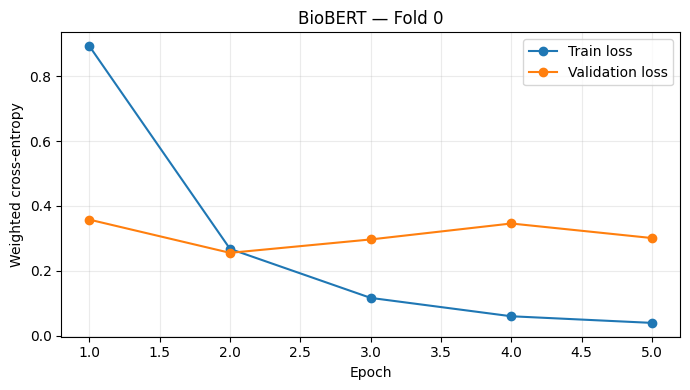


Results saved in: /content/causal_language_reproduction/results/fold_0
Prediction rows: 613
Total elapsed seconds: 283.5

MODULE 5D FOLD 0 TRAINING COMPLETED


In [ ]:

# MODULE 5D: BioBERT Fold 0 training and evaluation

import gc
import json
import hashlib
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.optim import Optimizer
from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader
from transformers import BertModel, BertTokenizer
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)

# -----------------------------
# 1. Configuration
# -----------------------------
PROJECT = Path("/content/causal_language_reproduction")
OUT = PROJECT / "results" / "fold_0"
OUT.mkdir(parents=True, exist_ok=True)

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

SEED = 0
EPOCHS = 5
LR = 2e-5
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 8
TOTAL_STEPS = 365

assert "PubMedDataset" in globals()
assert "collate_batch" in globals()
assert "df" in globals()
assert "manifest" in globals()
assert manifest["fold"] == 0

# Recheck frozen manifest
manifest_bytes = (
    PROJECT / "data/manifests/fold_0.json"
).read_bytes()

manifest_hash = hashlib.sha256(manifest_bytes).hexdigest()

assert manifest_hash == (
    "8394446e5abafb1616db22f7921f7902abfadd1286feeadda4268e2660b6eb45"
), "Fold manifest has changed."

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Release old model objects from earlier tests
for name in [
    "fresh_classifier", "classifier", "encoder", "model"
]:
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

# -----------------------------
# 2. Datasets and fresh loaders
# -----------------------------
fit_ds = PubMedDataset(df, manifest["fit_indices"])
val_ds = PubMedDataset(df, manifest["validation_indices"])
test_ds = PubMedDataset(df, manifest["test_indices"])

# Reuse the already validated tokenizer
tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

train_generator = torch.Generator().manual_seed(SEED)

train_dl = DataLoader(
    fit_ds, batch_size=BATCH_SIZE,
    shuffle=True, generator=train_generator,
    num_workers=0, collate_fn=collate_batch
)

val_dl = DataLoader(
    val_ds, batch_size=EVAL_BATCH_SIZE,
    shuffle=False, num_workers=0,
    collate_fn=collate_batch
)

test_dl = DataLoader(
    test_ds, batch_size=EVAL_BATCH_SIZE,
    shuffle=False, num_workers=0,
    collate_fn=collate_batch
)

assert len(train_dl) == 73
assert len(train_dl) * EPOCHS == TOTAL_STEPS

# -----------------------------
# 3. Fresh BioBERT classifier
# -----------------------------
base_model, info = BertModel.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    use_safetensors=False,
    output_loading_info=True
)

assert not info.get("missing_keys")
assert not info.get("mismatched_keys")
assert not info.get("error_msgs")

class FoldClassifier(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.bert = encoder
        self.dropout = nn.Dropout(
            encoder.config.hidden_dropout_prob
        )
        self.classifier = nn.Linear(
            encoder.config.hidden_size, 4
        )

    def forward(self, input_ids, attention_mask,
                token_type_ids=None):
        result = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        return self.classifier(
            self.dropout(result.pooler_output)
        )

model = FoldClassifier(base_model)

# Historical head initialization
torch.manual_seed(SEED)
with torch.no_grad():
    nn.init.normal_(
        model.classifier.weight, mean=0.0, std=0.02
    )
    nn.init.zeros_(model.classifier.bias)

model = model.to(device)

# -----------------------------
# 4. Historical-style optimizer
# -----------------------------
class HistoricalBertAdam(Optimizer):
    def __init__(self, params, lr=2e-5,
                 total_steps=365, warmup=0.1):
        super().__init__(params, dict(
            lr=lr, total_steps=total_steps,
            warmup=warmup, b1=0.9, b2=0.999,
            eps=1e-6, max_grad_norm=1.0
        ))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                if p.grad.is_sparse:
                    raise RuntimeError("Sparse gradient")

                clip_grad_norm_(
                    p, group["max_grad_norm"]
                )

                state = self.state[p]
                if len(state) == 0:
                    state["step"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)

                g = p.grad
                b1, b2 = group["b1"], group["b2"]

                state["m"].mul_(b1).add_(
                    g, alpha=1-b1
                )
                state["v"].mul_(b2).addcmul_(
                    g, g, value=1-b2
                )

                update = state["m"] / (
                    state["v"].sqrt() + group["eps"]
                )

                if group["weight_decay"] > 0:
                    update = (
                        update + group["weight_decay"] * p
                    )

                progress = (
                    state["step"] / group["total_steps"]
                )
                warmup = group["warmup"]

                factor = (
                    progress / warmup
                    if progress < warmup
                    else max(
                        (progress - 1) / (warmup - 1),
                        0.0
                    )
                )

                p.add_(
                    update, alpha=-group["lr"] * factor
                )
                state["step"] += 1

no_decay = [
    "bias", "LayerNorm.bias", "LayerNorm.weight"
]

named = list(model.named_parameters())

groups = [
    {
        "params": [
            p for n, p in named
            if not any(x in n for x in no_decay)
        ],
        "weight_decay": 0.01
    },
    {
        "params": [
            p for n, p in named
            if any(x in n for x in no_decay)
        ],
        "weight_decay": 0.0
    }
]

optimizer = HistoricalBertAdam(
    groups, lr=LR, total_steps=TOTAL_STEPS,
    warmup=0.1
)

counts = torch.tensor(
    [1356, 494, 213, 998],
    dtype=torch.float32, device=device
)
weights = counts.sum() / (4 * counts)

def get_inputs(batch):
    return {
        key: batch[key].to(device)
        for key in [
            "input_ids", "attention_mask", "token_type_ids"
        ]
    }

# -----------------------------
# 5. Validation / test function
# -----------------------------
def evaluate(loader, return_predictions=False):
    model.eval()

    all_true, all_pred, all_proba, all_ids = [], [], [], []
    total_loss = 0.0
    total_count = 0

    with torch.inference_mode():
        for batch in loader:
            logits = model(**get_inputs(batch))
            labels = batch["labels"].to(device)

            losses = F.cross_entropy(
                logits, labels,
                weight=weights,
                reduction="none"
            )

            probabilities = torch.softmax(
                logits, dim=-1
            )

            total_loss += losses.sum().item()
            total_count += len(labels)

            all_true.extend(labels.cpu().tolist())
            all_pred.extend(
                probabilities.argmax(dim=-1).cpu().tolist()
            )

            if return_predictions:
                all_proba.extend(
                    probabilities.cpu().tolist()
                )
                all_ids.extend(batch["row_ids"].tolist())

    result = {
        "loss": total_loss / total_count,
        "accuracy": accuracy_score(all_true, all_pred),
        "macro_f1": f1_score(
            all_true, all_pred,
            labels=[0, 1, 2, 3],
            average="macro", zero_division=0
        )
    }

    if return_predictions:
        result.update({
            "y_true": all_true,
            "y_pred": all_pred,
            "probabilities": all_proba,
            "row_ids": all_ids
        })

    return result

# -----------------------------
# 6. Five-epoch Fold 0 training
# -----------------------------
history = []
start = time.time()

print("=== FOLD 0 TRAINING ===", flush=True)
print("Device:", device, flush=True)
print("Fit / Val / Test:",
      len(fit_ds), len(val_ds), len(test_ds),
      flush=True)
print("Optimizer steps:", TOTAL_STEPS, flush=True)

for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_loss_sum = 0.0
    epoch_samples = 0

    for step, batch in enumerate(train_dl):
        optimizer.zero_grad(set_to_none=True)

        logits = model(**get_inputs(batch))
        labels = batch["labels"].to(device)

        loss = F.cross_entropy(
            logits, labels,
            weight=weights,
            reduction="none"
        ).mean()

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Nonfinite loss at epoch {epoch}, batch {step}"
            )

        loss.backward()
        optimizer.step()

        batch_size = len(labels)
        epoch_loss_sum += loss.item() * batch_size
        epoch_samples += batch_size

    val = evaluate(val_dl)

    row = {
        "epoch": epoch,
        "train_loss": epoch_loss_sum / epoch_samples,
        "val_loss": val["loss"],
        "val_accuracy": val["accuracy"],
        "val_macro_f1": val["macro_f1"]
    }

    history.append(row)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss={row['train_loss']:.4f} | "
        f"val loss={row['val_loss']:.4f} | "
        f"val acc={row['val_accuracy']:.4f} | "
        f"val macro-F1={row['val_macro_f1']:.4f}",
        flush=True
    )

# -----------------------------
# 7. Final-epoch test evaluation
# -----------------------------
test = evaluate(
    test_dl, return_predictions=True
)

assert len(test["row_ids"]) == len(test_ds)
assert set(test["row_ids"]) == set(
    manifest["test_indices"]
)
assert len(set(test["row_ids"])) == len(test_ds)

print("\n=== HELD-OUT FOLD 0 RESULTS ===")
print("Accuracy:", test["accuracy"])
print("Macro-F1:", test["macro_f1"])
print("\nClassification report:")
print(classification_report(
    test["y_true"], test["y_pred"],
    labels=[0, 1, 2, 3],
    zero_division=0
))

# -----------------------------
# 8. Save results and checkpoint
# -----------------------------
history_df = pd.DataFrame(history)
history_df.to_csv(
    OUT / "training_history.csv", index=False
)

pred_df = pd.DataFrame({
    "row_id": test["row_ids"],
    "true_label": test["y_true"],
    "pred_label": test["y_pred"]
})

for c in range(4):
    pred_df[f"p{c}"] = [
        p[c] for p in test["probabilities"]
    ]

pred_df.to_csv(
    OUT / "test_predictions.csv", index=False
)

metadata = {
    "fold": 0,
    "model_id": MODEL_ID,
    "revision": REVISION,
    "dataset_manifest_sha256": manifest_hash,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "max_seq_length": 128,
    "learning_rate": LR,
    "warmup": 0.1,
    "optimizer": "historical_BertAdam_adaptation",
    "seed": SEED,
    "internal_split": "saved_seeded_randperm",
    "num_workers": 0,
    "accuracy": test["accuracy"],
    "macro_f1": test["macro_f1"],
    "seconds_elapsed": time.time() - start
}

with open(OUT / "metrics.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Final epoch only, matching the reference selection rule
torch.save(
    model.state_dict(),
    OUT / "final_model_state.pt"
)

# -----------------------------
# 9. Basic training plot
# -----------------------------
plt.figure(figsize=(7, 4))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o", label="Train loss"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o", label="Validation loss"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy")
plt.title("BioBERT — Fold 0")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    OUT / "loss_curve.png", dpi=150
)
plt.show()

print("\nResults saved in:", OUT)
print("Prediction rows:", len(pred_df))
print("Total elapsed seconds:",
      round(metadata["seconds_elapsed"], 1))
print("\nMODULE 5D FOLD 0 TRAINING COMPLETED")


In [ ]:

# MODULE 5E: Independent Fold 0 results audit
# Read-only: does not train or change model weights.

from pathlib import Path
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

ROOT = Path("/content/causal_language_reproduction")
OUT = ROOT / "results" / "fold_0"

pred = pd.read_csv(OUT / "test_predictions.csv")
history = pd.read_csv(OUT / "training_history.csv")

with open(OUT / "metrics.json") as f:
    metrics = json.load(f)

with open(ROOT / "data/manifests/fold_0.json") as f:
    manifest = json.load(f)

original = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv"
)

print("=== SAVED FILE AUDIT ===")
print("Prediction shape:", pred.shape)
print("History shape:", history.shape)
print("Checkpoint exists:",
      (OUT / "final_model_state.pt").is_file())
print("Loss plot exists:",
      (OUT / "loss_curve.png").is_file())

assert len(pred) == 613
assert len(history) == 5

required = [
    "row_id", "true_label", "pred_label",
    "p0", "p1", "p2", "p3"
]
assert all(c in pred.columns for c in required)
assert not pred[required].isna().any().any()

# Check original row identities
row_ids = pred["row_id"].to_numpy()

assert len(np.unique(row_ids)) == len(row_ids)
assert set(row_ids) == set(manifest["test_indices"])

# Verify gold labels directly against the original dataset
gold = original.iloc[row_ids]["label"].to_numpy()
assert np.array_equal(
    gold, pred["true_label"].to_numpy()
)

# Check class probabilities
probs = pred[["p0", "p1", "p2", "p3"]].to_numpy()

assert probs.shape == (613, 4)
assert np.isfinite(probs).all()
assert np.all((probs >= 0) & (probs <= 1))
assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-5)

predicted = probs.argmax(axis=1)

assert np.array_equal(
    predicted, pred["pred_label"].to_numpy()
)

# Independently recompute evaluation
y_true = pred["true_label"].to_numpy()
y_pred = pred["pred_label"].to_numpy()

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred,
    labels=[0, 1, 2, 3],
    average="macro",
    zero_division=0
)

assert abs(accuracy - metrics["accuracy"]) < 1e-10
assert abs(macro_f1 - metrics["macro_f1"]) < 1e-10

cm = confusion_matrix(
    y_true, y_pred, labels=[0, 1, 2, 3]
)

print("\n=== INDEPENDENT METRICS ===")
print("Accuracy:", accuracy)
print("Macro-F1:", macro_f1)
print("Correct predictions:", (y_true == y_pred).sum())
print("Incorrect predictions:", (y_true != y_pred).sum())

print("\nConfusion matrix:")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3],
    zero_division=0
))

print("\n=== VALIDATION CHECKS ===")
print("Row alignment: PASSED")
print("Probability normalization: PASSED")
print("Prediction argmax agreement: PASSED")
print("Saved metrics agreement: PASSED")
print("Checkpoint size (bytes):",
      (OUT / "final_model_state.pt").stat().st_size)

print("\nMODULE 5E PREDICTION AUDIT PASSED")


=== SAVED FILE AUDIT ===
Prediction shape: (613, 7)
History shape: (5, 5)
Checkpoint exists: True
Loss plot exists: True

=== INDEPENDENT METRICS ===
Accuracy: 0.8907014681892332
Macro-F1: 0.87839960508921
Correct predictions: 546
Incorrect predictions: 67

Confusion matrix:
[[234  13  10  15]
 [  6  87   2   3]
 [  2   0  41   0]
 [ 11   4   1 184]]

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.86      0.89       272
           1       0.84      0.89      0.86        98
           2       0.76      0.95      0.85        43
           3       0.91      0.92      0.92       200

    accuracy                           0.89       613
   macro avg       0.86      0.91      0.88       613
weighted avg       0.89      0.89      0.89       613


=== VALIDATION CHECKS ===
Row alignment: PASSED
Probability normalization: PASSED
Prediction argmax agreement: PASSED
Saved metrics agreement: PASSED
Checkpoint size (bytes): 433337475

M

In [ ]:

# MODULE 5F: Verify checkpoint restoration
# No training, optimizer steps, or file modifications.

from pathlib import Path
import gc
import numpy as np
import pandas as pd
import torch
from transformers import BertConfig, BertModel, BertTokenizer

ROOT = Path("/content/causal_language_reproduction")
OUT = ROOT / "results/fold_0"
MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

assert "FoldClassifier" in globals(), (
    "Run Module 5D first to define FoldClassifier."
)

checkpoint_path = OUT / "final_model_state.pt"
prediction_path = OUT / "test_predictions.csv"

assert checkpoint_path.is_file()
assert prediction_path.is_file()

pred = pd.read_csv(prediction_path)
assert len(pred) == 613

# Release trained objects to reduce GPU memory usage.
for name in [
    "model", "base_model", "optimizer",
    "fresh_classifier", "classifier", "encoder"
]:
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Construct architecture without downloading pretrained weights.
config = BertConfig.from_pretrained(
    MODEL_ID, revision=REVISION
)
restored_model = FoldClassifier(BertModel(config))

# Load all trained tensors from the saved checkpoint.
state = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

load_result = restored_model.load_state_dict(
    state, strict=True
)

del state
gc.collect()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

restored_model.to(device)
restored_model.eval()

tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

original = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv",
    keep_default_na=False
)

# Take eight saved held-out predictions.
sample = pred.head(8).copy()
row_ids = sample["row_id"].astype(int).tolist()

sentences = (
    original.iloc[row_ids]["sentence"]
    .str.strip()
    .tolist()
)

batch = tokenizer(
    sentences,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

batch = {
    key: value.to(device)
    for key, value in batch.items()
}

with torch.inference_mode():
    logits = restored_model(**batch)
    probabilities = torch.softmax(
        logits, dim=-1
    ).cpu().numpy()

saved_probabilities = sample[
    ["p0", "p1", "p2", "p3"]
].to_numpy()

max_difference = np.max(
    np.abs(probabilities - saved_probabilities)
)

restored_labels = probabilities.argmax(axis=1)
saved_labels = sample["pred_label"].to_numpy()

print("=== CHECKPOINT RESTORATION AUDIT ===")
print("Device:", device)
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)
print("Restored logits:", tuple(logits.shape))
print("Predicted labels:", restored_labels.tolist())
print("Saved labels:", saved_labels.tolist())
print("Maximum probability difference:",
      float(max_difference))

assert logits.shape == (8, 4)
assert not load_result.missing_keys
assert not load_result.unexpected_keys
assert np.array_equal(restored_labels, saved_labels)
assert np.allclose(
    probabilities,
    saved_probabilities,
    rtol=1e-4,
    atol=1e-5
)

print("Checkpoint restored successfully: True")
print("Saved predictions reproduced: True")
print("\nMODULE 5F CHECKPOINT RESTORATION PASSED")


=== CHECKPOINT RESTORATION AUDIT ===
Device: cuda
Missing keys: []
Unexpected keys: []
Restored logits: (8, 4)
Predicted labels: [0, 1, 0, 0, 0, 3, 0, 0]
Saved labels: [0, 1, 0, 0, 0, 3, 0, 0]
Maximum probability difference: 6.053596643060266e-09
Checkpoint restored successfully: True
Saved predictions reproduced: True

MODULE 5F CHECKPOINT RESTORATION PASSED


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== FOLD 1 TRAINING ===
Device: cuda
Fit / Val / Test: 2327 122 612
Optimizer steps: 365
Epoch 1/5 | train loss=0.9219 | val loss=0.4484 | val acc=0.8525 | val macro-F1=0.8270
Epoch 2/5 | train loss=0.2859 | val loss=0.3169 | val acc=0.8607 | val macro-F1=0.8414
Epoch 3/5 | train loss=0.0966 | val loss=0.2781 | val acc=0.9180 | val macro-F1=0.8998
Epoch 4/5 | train loss=0.0418 | val loss=0.2654 | val acc=0.9098 | val macro-F1=0.8898
Epoch 5/5 | train loss=0.0273 | val loss=0.2693 | val acc=0.9098 | val macro-F1=0.8898

=== FOLD 1 HELD-OUT RESULTS ===
Accuracy: 0.9003267973856209
Macro-F1: 0.8874202608112423
              precision    recall  f1-score   support

           0       0.90      0.90      0.90       271
           1       0.90      0.86      0.88        99
           2       0.86      0.84      0.85        43
           3       0.91      0.94      0.92       199

    accuracy                           0.90       612
   macro avg       0.89      0.88      0.89       612
weigh

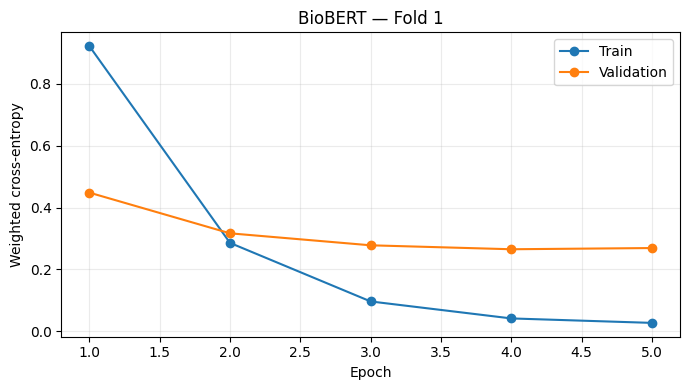


Prediction rows: 612
Saved to: /content/causal_language_reproduction/results/fold_1
MODULE 5G FOLD 1 TRAINING COMPLETED


In [ ]:

# MODULE 5G: Train and evaluate Fold 1 only
# Reuses the validated components from Modules 5B and 5D.

from pathlib import Path
import json
import hashlib
import random
import gc
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from transformers import BertModel, BertTokenizer
from sklearn.metrics import accuracy_score, f1_score, classification_report

ROOT = Path("/content/causal_language_reproduction")
FOLD = 1
OUT = ROOT / "results" / f"fold_{FOLD}"
OUT.mkdir(parents=True, exist_ok=True)

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

SEED = 0
EPOCHS = 5
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 8

# Confirm that earlier definitions are available.
for name in [
    "FoldClassifier", "HistoricalBertAdam",
    "PubMedDataset", "collate_batch"
]:
    assert name in globals(), f"Missing {name}: rerun its defining cell."

# 1. Load the frozen Fold 1 partition
manifest_path = ROOT / "data/manifests/fold_1.json"
manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)

manifest_hash = hashlib.sha256(manifest_bytes).hexdigest()

assert manifest["fold"] == FOLD

df = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv",
    usecols=["sentence", "label"],
    keep_default_na=False
)
df["sentence"] = df["sentence"].str.strip()

fit_ids = manifest["fit_indices"]
val_ids = manifest["validation_indices"]
test_ids = manifest["test_indices"]

assert (len(fit_ids), len(val_ids), len(test_ids)) == (
    2327, 122, 612
)

assert len(set(fit_ids) & set(test_ids)) == 0
assert len(set(val_ids) & set(test_ids)) == 0
assert len(set(fit_ids) & set(val_ids)) == 0

# 2. Reset random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Clear previous test models to reduce memory use
for name in ["model", "restored_model", "base_model", "optimizer"]:
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 3. Construct data loaders
tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID, revision=REVISION, do_lower_case=False
)

fit_ds = PubMedDataset(df, fit_ids)
val_ds = PubMedDataset(df, val_ids)
test_ds = PubMedDataset(df, test_ids)

generator = torch.Generator().manual_seed(SEED)

train_dl = DataLoader(
    fit_ds, batch_size=BATCH_SIZE,
    shuffle=True, generator=generator,
    num_workers=0, collate_fn=collate_batch
)

val_dl = DataLoader(
    val_ds, batch_size=EVAL_BATCH_SIZE,
    shuffle=False, num_workers=0,
    collate_fn=collate_batch
)

test_dl = DataLoader(
    test_ds, batch_size=EVAL_BATCH_SIZE,
    shuffle=False, num_workers=0,
    collate_fn=collate_batch
)

total_steps = len(train_dl) * EPOCHS
assert total_steps == 365

# 4. Construct a completely fresh model
base_model, loading_info = BertModel.from_pretrained(
    MODEL_ID, revision=REVISION,
    use_safetensors=False,
    output_loading_info=True
)

assert not loading_info.get("missing_keys")
assert not loading_info.get("mismatched_keys")
assert not loading_info.get("error_msgs")

model = FoldClassifier(base_model)

torch.manual_seed(SEED)

with torch.no_grad():
    nn.init.normal_(
        model.classifier.weight,
        mean=0.0, std=0.02
    )
    nn.init.zeros_(model.classifier.bias)

model = model.to(device)

# 5. Historical optimizer parameter groups
no_decay = ["bias", "LayerNorm.bias", "LayerNorm.weight"]

named = list(model.named_parameters())

groups = [
    {
        "params": [
            p for n, p in named
            if not any(x in n for x in no_decay)
        ],
        "weight_decay": 0.01
    },
    {
        "params": [
            p for n, p in named
            if any(x in n for x in no_decay)
        ],
        "weight_decay": 0.0
    }
]

optimizer = HistoricalBertAdam(
    groups, lr=2e-5,
    total_steps=total_steps,
    warmup=0.1
)

counts = torch.tensor(
    [1356, 494, 213, 998],
    dtype=torch.float32, device=device
)
weights = counts.sum() / (4 * counts)

def move_inputs(batch):
    return {
        k: batch[k].to(device)
        for k in ["input_ids", "attention_mask", "token_type_ids"]
    }

def evaluate_fold(loader, with_predictions=False):
    model.eval()
    gold, predicted, probabilities, row_ids = [], [], [], []
    loss_sum = 0.0

    with torch.inference_mode():
        for batch in loader:
            logits = model(**move_inputs(batch))
            labels = batch["labels"].to(device)

            batch_loss = F.cross_entropy(
                logits, labels,
                weight=weights, reduction="none"
            )

            probs = torch.softmax(logits, dim=-1)

            loss_sum += batch_loss.sum().item()
            gold.extend(labels.cpu().tolist())
            predicted.extend(probs.argmax(-1).cpu().tolist())

            if with_predictions:
                probabilities.extend(probs.cpu().tolist())
                row_ids.extend(batch["row_ids"].tolist())

    result = {
        "loss": loss_sum / len(gold),
        "accuracy": accuracy_score(gold, predicted),
        "macro_f1": f1_score(
            gold, predicted, labels=[0, 1, 2, 3],
            average="macro", zero_division=0
        )
    }

    if with_predictions:
        result.update(
            gold=gold, predicted=predicted,
            probabilities=probabilities, row_ids=row_ids
        )

    return result

# 6. Train for five epochs
history = []
start = time.time()

print("=== FOLD 1 TRAINING ===", flush=True)
print("Device:", device, flush=True)
print("Fit / Val / Test:",
      len(fit_ds), len(val_ds), len(test_ds), flush=True)
print("Optimizer steps:", total_steps, flush=True)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_train_loss = 0.0
    sample_count = 0

    for step, batch in enumerate(train_dl):
        optimizer.zero_grad(set_to_none=True)

        logits = model(**move_inputs(batch))
        labels = batch["labels"].to(device)

        loss = F.cross_entropy(
            logits, labels,
            weight=weights, reduction="none"
        ).mean()

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Nonfinite loss: epoch={epoch}, batch={step}"
            )

        loss.backward()
        optimizer.step()

        n = len(labels)
        total_train_loss += loss.item() * n
        sample_count += n

    val = evaluate_fold(val_dl)

    record = {
        "epoch": epoch,
        "train_loss": total_train_loss / sample_count,
        "val_loss": val["loss"],
        "val_accuracy": val["accuracy"],
        "val_macro_f1": val["macro_f1"]
    }

    history.append(record)

    print(
        f"Epoch {epoch}/5 | "
        f"train loss={record['train_loss']:.4f} | "
        f"val loss={record['val_loss']:.4f} | "
        f"val acc={record['val_accuracy']:.4f} | "
        f"val macro-F1={record['val_macro_f1']:.4f}",
        flush=True
    )

# 7. Evaluate the untouched test fold
test = evaluate_fold(test_dl, with_predictions=True)

assert len(test["row_ids"]) == 612
assert len(set(test["row_ids"])) == 612
assert set(test["row_ids"]) == set(test_ids)

print("\n=== FOLD 1 HELD-OUT RESULTS ===")
print("Accuracy:", test["accuracy"])
print("Macro-F1:", test["macro_f1"])
print(classification_report(
    test["gold"], test["predicted"],
    labels=[0, 1, 2, 3], zero_division=0
))

# 8. Save artifacts
history_df = pd.DataFrame(history)
history_df.to_csv(OUT / "training_history.csv", index=False)

pred_df = pd.DataFrame({
    "row_id": test["row_ids"],
    "true_label": test["gold"],
    "pred_label": test["predicted"]
})

for c in range(4):
    pred_df[f"p{c}"] = [
        row[c] for row in test["probabilities"]
    ]

pred_df.to_csv(OUT / "test_predictions.csv", index=False)

metadata = {
    "fold": FOLD,
    "model_id": MODEL_ID,
    "revision": REVISION,
    "manifest_sha256": manifest_hash,
    "epochs": EPOCHS,
    "learning_rate": 2e-5,
    "train_batch_size": BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "max_seq_length": 128,
    "total_optimizer_steps": total_steps,
    "optimizer": "historical_BertAdam_adaptation",
    "seed": SEED,
    "internal_split": "saved_seeded_randperm",
    "num_workers": 0,
    "accuracy": test["accuracy"],
    "macro_f1": test["macro_f1"],
    "seconds_elapsed": time.time() - start
}

with open(OUT / "metrics.json", "w") as f:
    json.dump(metadata, f, indent=2)

torch.save(model.state_dict(), OUT / "final_model_state.pt")

plt.figure(figsize=(7, 4))
plt.plot(
    history_df["epoch"], history_df["train_loss"],
    marker="o", label="Train"
)
plt.plot(
    history_df["epoch"], history_df["val_loss"],
    marker="o", label="Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy")
plt.title("BioBERT — Fold 1")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "loss_curve.png", dpi=150)
plt.show()

print("\nPrediction rows:", len(pred_df))
print("Saved to:", OUT)
print("MODULE 5G FOLD 1 TRAINING COMPLETED")


In [ ]:

# MODULE 5H: Independent Fold 1 audit
# No training; no modification to saved results.

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

ROOT = Path("/content/causal_language_reproduction")
FOLD = 1
OUT = ROOT / "results" / f"fold_{FOLD}"

required_files = [
    "training_history.csv",
    "test_predictions.csv",
    "metrics.json",
    "final_model_state.pt",
    "loss_curve.png"
]

print("=== FOLD 1 ARTIFACT AUDIT ===")

for filename in required_files:
    path = OUT / filename
    print(filename, "exists:", path.is_file())
    assert path.is_file(), f"Missing file: {path}"

history = pd.read_csv(OUT / "training_history.csv")
pred = pd.read_csv(OUT / "test_predictions.csv")

with open(OUT / "metrics.json") as f:
    metrics = json.load(f)

manifest_path = ROOT / "data/manifests/fold_1.json"
manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)

original = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv",
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)

assert manifest["fold"] == FOLD
assert metrics["fold"] == FOLD
assert len(history) == 5
assert len(pred) == 612

print("\nTraining history rows:", len(history))
print("Prediction rows:", len(pred))

# ------------------------------------
# 1. Verify row and gold-label identity
# ------------------------------------

required_columns = [
    "row_id", "true_label", "pred_label",
    "p0", "p1", "p2", "p3"
]
assert all(c in pred.columns for c in required_columns)
assert not pred[required_columns].isna().any().any()

row_ids = pred["row_id"].to_numpy(dtype=int)

assert len(np.unique(row_ids)) == 612
assert set(row_ids) == set(manifest["test_indices"])

gold_from_original = original.iloc[row_ids]["label"].to_numpy()
y_true = pred["true_label"].to_numpy(dtype=int)
y_pred = pred["pred_label"].to_numpy(dtype=int)

assert np.array_equal(gold_from_original, y_true)
assert set(np.unique(y_true)).issubset({0, 1, 2, 3})
assert set(np.unique(y_pred)).issubset({0, 1, 2, 3})

# ------------------------------------
# 2. Verify probabilities
# ------------------------------------

probs = pred[["p0", "p1", "p2", "p3"]].to_numpy()

assert probs.shape == (612, 4)
assert np.isfinite(probs).all()
assert np.all((probs >= 0) & (probs <= 1))
assert np.allclose(
    probs.sum(axis=1), 1.0, atol=1e-5
)
assert np.array_equal(probs.argmax(axis=1), y_pred)

# ------------------------------------
# 3. Independently recompute metrics
# ------------------------------------

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred,
    labels=[0, 1, 2, 3],
    average="macro", zero_division=0
)

correct = int((y_true == y_pred).sum())
incorrect = int((y_true != y_pred).sum())

print("\n=== INDEPENDENT FOLD 1 METRICS ===")
print("Accuracy:", accuracy)
print("Macro-F1:", macro_f1)
print("Correct:", correct)
print("Incorrect:", incorrect)

assert np.isclose(
    accuracy, 0.9003267973856209, atol=1e-12
)
assert np.isclose(
    macro_f1, 0.8874202608112423, atol=1e-12
)

assert np.isclose(
    accuracy, metrics["accuracy"], atol=1e-12
)
assert np.isclose(
    macro_f1, metrics["macro_f1"], atol=1e-12
)

assert correct == 551
assert incorrect == 61

# ------------------------------------
# 4. Confusion matrix
# ------------------------------------

cm = confusion_matrix(
    y_true, y_pred, labels=[0, 1, 2, 3]
)

print("\nConfusion matrix:")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3],
    zero_division=0
))

assert cm.shape == (4, 4)
assert cm.sum() == 612
assert np.trace(cm) == 551

# ------------------------------------
# 5. Reproducibility and file integrity
# ------------------------------------

actual_manifest_hash = hashlib.sha256(
    manifest_bytes
).hexdigest()

assert metrics["manifest_sha256"] == actual_manifest_hash
assert metrics["epochs"] == 5
assert metrics["total_optimizer_steps"] == 365

checkpoint_path = OUT / "final_model_state.pt"

print("\n=== SAVED CHECKPOINT ===")
print("Checkpoint bytes:",
      checkpoint_path.stat().st_size)
print("Manifest SHA-256:", actual_manifest_hash)

assert checkpoint_path.stat().st_size > 0

print("\nRow alignment: PASSED")
print("Gold labels: PASSED")
print("Probabilities: PASSED")
print("Independent metrics: PASSED")
print("Manifest hash: PASSED")

print("\nMODULE 5H FOLD 1 PREDICTION AUDIT PASSED")


=== FOLD 1 ARTIFACT AUDIT ===
training_history.csv exists: True
test_predictions.csv exists: True
metrics.json exists: True
final_model_state.pt exists: True
loss_curve.png exists: True

Training history rows: 5
Prediction rows: 612

=== INDEPENDENT FOLD 1 METRICS ===
Accuracy: 0.9003267973856209
Macro-F1: 0.8874202608112423
Correct: 551
Incorrect: 61

Confusion matrix:
[[243   8   5  15]
 [  9  85   1   4]
 [  6   1  36   0]
 [ 12   0   0 187]]

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90       271
           1       0.90      0.86      0.88        99
           2       0.86      0.84      0.85        43
           3       0.91      0.94      0.92       199

    accuracy                           0.90       612
   macro avg       0.89      0.88      0.89       612
weighted avg       0.90      0.90      0.90       612


=== SAVED CHECKPOINT ===
Checkpoint bytes: 433337475
Manifest SHA-256: 74382afa8b44e52afe8

In [ ]:

# MODULE 5I: Restore Fold 1 checkpoint and verify all 612 predictions
# Read-only audit: no training and no saved-file modifications.

from pathlib import Path
import gc
import json
import numpy as np
import pandas as pd
import torch

from transformers import BertConfig, BertModel, BertTokenizer
from torch.utils.data import DataLoader

ROOT = Path("/content/causal_language_reproduction")
OUT = ROOT / "results/fold_1"

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

assert "FoldClassifier" in globals()
assert "PubMedDataset" in globals()
assert "collate_batch" in globals()

# 1. Load saved results and fold manifest
saved = pd.read_csv(OUT / "test_predictions.csv")

with open(ROOT / "data/manifests/fold_1.json") as f:
    fold_manifest = json.load(f)

assert len(saved) == 612
assert set(saved["row_id"]) == set(
    fold_manifest["test_indices"]
)

original = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv",
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)
original["sentence"] = original["sentence"].str.strip()

# 2. Release the old trained model
for name in ["model", "base_model", "optimizer",
             "restored_model"]:
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 3. Reconstruct architecture and restore all weights
config = BertConfig.from_pretrained(
    MODEL_ID, revision=REVISION
)

restored_model = FoldClassifier(BertModel(config))

state = torch.load(
    OUT / "final_model_state.pt",
    map_location="cpu",
    weights_only=True
)

load_info = restored_model.load_state_dict(
    state, strict=True
)

del state
gc.collect()

assert not load_info.missing_keys
assert not load_info.unexpected_keys

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

restored_model.to(device)
restored_model.eval()

tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

# 4. Build test loader in exact saved prediction order
ordered_ids = saved["row_id"].astype(int).tolist()

audit_dataset = PubMedDataset(
    original, ordered_ids
)

audit_loader = DataLoader(
    audit_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

# 5. Independently infer all test probabilities
new_ids = []
new_labels = []
new_probabilities = []

with torch.inference_mode():
    for batch in audit_loader:
        inputs = {
            key: batch[key].to(device)
            for key in [
                "input_ids",
                "attention_mask",
                "token_type_ids"
            ]
        }

        logits = restored_model(**inputs)
        probabilities = torch.softmax(
            logits, dim=-1
        )

        new_ids.extend(batch["row_ids"].tolist())
        new_labels.extend(
            probabilities.argmax(dim=-1).cpu().tolist()
        )
        new_probabilities.extend(
            probabilities.cpu().tolist()
        )

new_probabilities = np.asarray(new_probabilities)
saved_probabilities = saved[
    ["p0", "p1", "p2", "p3"]
].to_numpy()

new_labels = np.asarray(new_labels)
saved_labels = saved["pred_label"].to_numpy()

# 6. Audit exact row alignment and numerical agreement
assert new_ids == ordered_ids
assert new_probabilities.shape == (612, 4)

max_difference = float(
    np.max(
        np.abs(new_probabilities - saved_probabilities)
    )
)

mismatched_predictions = int(
    np.sum(new_labels != saved_labels)
)

print("=== FOLD 1 CHECKPOINT RESTORATION ===")
print("Device:", device)
print("Missing keys:", load_info.missing_keys)
print("Unexpected keys:", load_info.unexpected_keys)
print("Rows independently evaluated:", len(new_ids))
print("Mismatched predicted labels:", mismatched_predictions)
print("Maximum probability difference:", max_difference)

assert mismatched_predictions == 0

assert np.allclose(
    new_probabilities,
    saved_probabilities,
    rtol=1e-4,
    atol=1e-5
)

print("\nCheckpoint restored successfully: True")
print("All 612 predictions reproduced: True")
print("Probability comparison: PASSED")
print("\nMODULE 5I FOLD 1 CHECKPOINT AUDIT PASSED")


=== FOLD 1 CHECKPOINT RESTORATION ===
Device: cuda
Missing keys: []
Unexpected keys: []
Rows independently evaluated: 612
Mismatched predicted labels: 0
Maximum probability difference: 1.6689300537664487e-06

Checkpoint restored successfully: True
All 612 predictions reproduced: True
Probability comparison: PASSED

MODULE 5I FOLD 1 CHECKPOINT AUDIT PASSED


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== FOLD 2 TRAINING ===
Device: cuda
Fit / Val / Test: 2327 122 612
Optimizer steps: 365
Epoch 1/5 | train loss=0.8469 | val loss=0.4986 | val acc=0.8279 | val macro-F1=0.7941
Epoch 2/5 | train loss=0.2532 | val loss=0.4432 | val acc=0.8443 | val macro-F1=0.8062
Epoch 3/5 | train loss=0.0857 | val loss=0.5237 | val acc=0.8689 | val macro-F1=0.8426
Epoch 4/5 | train loss=0.0295 | val loss=0.5861 | val acc=0.8689 | val macro-F1=0.8355
Epoch 5/5 | train loss=0.0170 | val loss=0.6135 | val acc=0.8689 | val macro-F1=0.8355

=== FOLD 2 HELD-OUT RESULTS ===
Accuracy: 0.9003267973856209
Macro-F1: 0.8834951149560418
              precision    recall  f1-score   support

           0       0.93      0.89      0.91       271
           1       0.86      0.83      0.85        99
           2       0.88      0.84      0.86        43
           3       0.88      0.96      0.92       199

    accuracy                           0.90       612
   macro avg       0.89      0.88      0.88       612
weigh

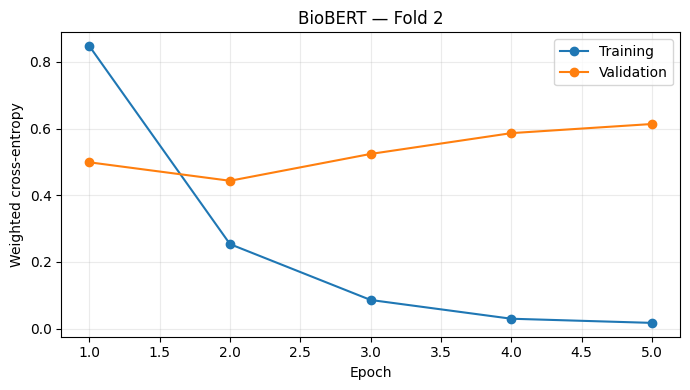


Prediction rows: 612
Saved to: /content/causal_language_reproduction/results/fold_2
MODULE 5J FOLD 2 TRAINING COMPLETED


In [ ]:

# MODULE 5J — FOLD 2 TRAINING
# Run in the same Colab runtime as the earlier modules.
# Does not change Fold 0 or Fold 1 artifacts.

import gc
import json
import hashlib
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from transformers import BertModel, BertTokenizer
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)

ROOT = Path("/content/causal_language_reproduction")
FOLD = 2
OUT = ROOT / "results" / f"fold_{FOLD}"

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

SEED = 0
EPOCHS = 5
TRAIN_BATCH = 32
EVAL_BATCH = 8
LR = 2e-5
MAX_LENGTH = 128

# Ensure earlier validated definitions still exist.
for name in [
    "FoldClassifier",
    "HistoricalBertAdam",
    "PubMedDataset",
    "collate_batch"
]:
    assert name in globals(), f"Missing required definition: {name}"

# Prevent accidental overwrite of completed Fold 2 results.
if OUT.exists():
    assert not any(OUT.iterdir()), (
        f"{OUT} already contains files. "
        "Inspect existing results before rerunning."
    )
OUT.mkdir(parents=True, exist_ok=True)

# -----------------------------------------
# 1. Load original dataset and frozen split
# -----------------------------------------

DATA_FILE = (
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv"
)

df = pd.read_csv(
    DATA_FILE,
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)
df["sentence"] = df["sentence"].str.strip()

manifest_path = ROOT / "data/manifests/fold_2.json"
manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)

manifest_hash = hashlib.sha256(
    manifest_bytes
).hexdigest()

assert manifest["fold"] == 2
assert len(df) == 3061

fit_ids = manifest["fit_indices"]
val_ids = manifest["validation_indices"]
test_ids = manifest["test_indices"]

assert (
    len(fit_ids), len(val_ids), len(test_ids)
) == (2327, 122, 612)

a, b, c = map(set, [fit_ids, val_ids, test_ids])
assert a.isdisjoint(b)
assert a.isdisjoint(c)
assert b.isdisjoint(c)
assert len(a | b | c) == 3061

# -----------------------------------------
# 2. Reset random state
# -----------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Free previous trained/restored models.
for name in [
    "model", "restored_model", "base_model",
    "optimizer", "fresh_classifier", "classifier"
]:
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# -----------------------------------------
# 3. Build DataLoaders
# -----------------------------------------

tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

fit_ds = PubMedDataset(df, fit_ids)
val_ds = PubMedDataset(df, val_ids)
test_ds = PubMedDataset(df, test_ids)

generator = torch.Generator().manual_seed(SEED)

train_dl = DataLoader(
    fit_ds,
    batch_size=TRAIN_BATCH,
    shuffle=True,
    generator=generator,
    num_workers=0,
    collate_fn=collate_batch
)

val_dl = DataLoader(
    val_ds,
    batch_size=EVAL_BATCH,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

test_dl = DataLoader(
    test_ds,
    batch_size=EVAL_BATCH,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

total_steps = len(train_dl) * EPOCHS

assert len(train_dl) == 73
assert total_steps == 365

# -----------------------------------------
# 4. Fresh pretrained BioBERT
# -----------------------------------------

base_model, loading_info = BertModel.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    use_safetensors=False,
    output_loading_info=True
)

assert not loading_info.get("missing_keys")
assert not loading_info.get("mismatched_keys")
assert not loading_info.get("error_msgs")

model = FoldClassifier(base_model)

# Match earlier head initialization.
torch.manual_seed(SEED)

with torch.no_grad():
    nn.init.normal_(
        model.classifier.weight,
        mean=0.0,
        std=0.02
    )
    nn.init.zeros_(model.classifier.bias)

model = model.to(device)

# -----------------------------------------
# 5. Historical optimizer configuration
# -----------------------------------------

no_decay = [
    "bias", "LayerNorm.bias", "LayerNorm.weight"
]

named = list(model.named_parameters())

decay_params = [
    p for n, p in named
    if not any(x in n for x in no_decay)
]

no_decay_params = [
    p for n, p in named
    if any(x in n for x in no_decay)
]

assert len(decay_params) == 77
assert len(no_decay_params) == 124

groups = [
    {
        "params": decay_params,
        "weight_decay": 0.01
    },
    {
        "params": no_decay_params,
        "weight_decay": 0.0
    }
]

optimizer = HistoricalBertAdam(
    groups,
    lr=LR,
    total_steps=total_steps,
    warmup=0.1
)

# Original full-corpus class weights.
counts = torch.tensor(
    [1356, 494, 213, 998],
    dtype=torch.float32,
    device=device
)

weights = counts.sum() / (4 * counts)

# -----------------------------------------
# 6. Evaluation helpers
# -----------------------------------------

def move_inputs(batch):
    return {
        key: batch[key].to(device)
        for key in [
            "input_ids",
            "attention_mask",
            "token_type_ids"
        ]
    }

def evaluate_fold(loader, save_predictions=False):
    model.eval()

    gold = []
    predicted = []
    probabilities = []
    row_ids = []
    loss_sum = 0.0

    with torch.inference_mode():
        for batch in loader:
            inputs = move_inputs(batch)
            labels = batch["labels"].to(device)

            logits = model(**inputs)

            losses = F.cross_entropy(
                logits,
                labels,
                weight=weights,
                reduction="none"
            )

            probs = torch.softmax(logits, dim=-1)

            loss_sum += losses.sum().item()

            gold.extend(labels.cpu().tolist())
            predicted.extend(
                probs.argmax(dim=-1).cpu().tolist()
            )

            if save_predictions:
                probabilities.extend(
                    probs.cpu().tolist()
                )
                row_ids.extend(
                    batch["row_ids"].tolist()
                )

    result = {
        "loss": loss_sum / len(gold),
        "accuracy": accuracy_score(gold, predicted),
        "macro_f1": f1_score(
            gold,
            predicted,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )
    }

    if save_predictions:
        result.update({
            "gold": gold,
            "predicted": predicted,
            "probabilities": probabilities,
            "row_ids": row_ids
        })

    return result

# -----------------------------------------
# 7. Train exactly five epochs
# -----------------------------------------

history = []
start = time.time()

print("=== FOLD 2 TRAINING ===", flush=True)
print("Device:", device, flush=True)
print(
    "Fit / Val / Test:",
    len(fit_ds), len(val_ds), len(test_ds),
    flush=True
)
print("Optimizer steps:", total_steps, flush=True)

for epoch in range(1, EPOCHS + 1):
    model.train()

    train_loss_sum = 0.0
    train_count = 0

    for batch_number, batch in enumerate(train_dl):
        optimizer.zero_grad(set_to_none=True)

        labels = batch["labels"].to(device)
        logits = model(**move_inputs(batch))

        loss = F.cross_entropy(
            logits,
            labels,
            weight=weights,
            reduction="none"
        ).mean()

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Nonfinite loss at epoch {epoch}, "
                f"batch {batch_number}"
            )

        loss.backward()
        optimizer.step()

        n = len(labels)
        train_loss_sum += loss.item() * n
        train_count += n

    validation = evaluate_fold(val_dl)

    record = {
        "epoch": epoch,
        "train_loss": train_loss_sum / train_count,
        "val_loss": validation["loss"],
        "val_accuracy": validation["accuracy"],
        "val_macro_f1": validation["macro_f1"]
    }

    history.append(record)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss={record['train_loss']:.4f} | "
        f"val loss={record['val_loss']:.4f} | "
        f"val acc={record['val_accuracy']:.4f} | "
        f"val macro-F1={record['val_macro_f1']:.4f}",
        flush=True
    )

# -----------------------------------------
# 8. Final-epoch test evaluation
# -----------------------------------------

test = evaluate_fold(
    test_dl,
    save_predictions=True
)

assert len(test["row_ids"]) == 612
assert len(set(test["row_ids"])) == 612
assert set(test["row_ids"]) == set(test_ids)

print("\n=== FOLD 2 HELD-OUT RESULTS ===")
print("Accuracy:", test["accuracy"])
print("Macro-F1:", test["macro_f1"])

print(
    classification_report(
        test["gold"],
        test["predicted"],
        labels=[0, 1, 2, 3],
        zero_division=0
    )
)

# -----------------------------------------
# 9. Save experimental artifacts
# -----------------------------------------

history_df = pd.DataFrame(history)
history_df.to_csv(
    OUT / "training_history.csv",
    index=False
)

pred_df = pd.DataFrame({
    "row_id": test["row_ids"],
    "true_label": test["gold"],
    "pred_label": test["predicted"]
})

for class_id in range(4):
    pred_df[f"p{class_id}"] = [
        row[class_id]
        for row in test["probabilities"]
    ]

pred_df.to_csv(
    OUT / "test_predictions.csv",
    index=False
)

metrics = {
    "fold": FOLD,
    "model_id": MODEL_ID,
    "revision": REVISION,
    "manifest_sha256": manifest_hash,
    "epochs": EPOCHS,
    "learning_rate": LR,
    "train_batch_size": TRAIN_BATCH,
    "eval_batch_size": EVAL_BATCH,
    "max_seq_length": MAX_LENGTH,
    "total_optimizer_steps": total_steps,
    "optimizer": "historical_BertAdam_adaptation",
    "seed": SEED,
    "internal_split": "saved_seeded_randperm",
    "num_workers": 0,
    "accuracy": test["accuracy"],
    "macro_f1": test["macro_f1"],
    "seconds_elapsed": time.time() - start
}

with open(OUT / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Save final epoch, not the best validation epoch.
torch.save(
    model.state_dict(),
    OUT / "final_model_state.pt"
)

plt.figure(figsize=(7, 4))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy")
plt.title("BioBERT — Fold 2")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "loss_curve.png", dpi=150)
plt.show()

print("\nPrediction rows:", len(pred_df))
print("Saved to:", OUT)
print("MODULE 5J FOLD 2 TRAINING COMPLETED")


In [ ]:

# MODULE 5K: Independent Fold 2 artifact and prediction audit
# No training and no file modifications.

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

ROOT = Path("/content/causal_language_reproduction")
FOLD = 2
OUT = ROOT / "results" / f"fold_{FOLD}"

# 1. Check saved artifacts
required_files = [
    "training_history.csv",
    "test_predictions.csv",
    "metrics.json",
    "final_model_state.pt",
    "loss_curve.png"
]

print("=== FOLD 2 ARTIFACT AUDIT ===")

for filename in required_files:
    file_path = OUT / filename
    print(filename, "exists:", file_path.is_file())
    assert file_path.is_file(), f"Missing: {filename}"

history = pd.read_csv(OUT / "training_history.csv")
pred = pd.read_csv(OUT / "test_predictions.csv")

with open(OUT / "metrics.json") as f:
    metrics = json.load(f)

manifest_path = ROOT / "data/manifests/fold_2.json"
manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)

original = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv",
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)

assert len(original) == 3061
assert len(history) == 5
assert history["epoch"].tolist() == [1, 2, 3, 4, 5]
assert len(pred) == 612
assert manifest["fold"] == metrics["fold"] == FOLD

print("\nHistory rows:", len(history))
print("Prediction rows:", len(pred))

# 2. Validate original row IDs and labels
required_columns = [
    "row_id", "true_label", "pred_label",
    "p0", "p1", "p2", "p3"
]

assert all(c in pred.columns for c in required_columns)
assert not pred[required_columns].isna().any().any()

row_ids = pred["row_id"].to_numpy(dtype=int)
y_true = pred["true_label"].to_numpy(dtype=int)
y_pred = pred["pred_label"].to_numpy(dtype=int)

assert len(np.unique(row_ids)) == 612
assert set(row_ids) == set(manifest["test_indices"])

gold_labels = original.iloc[row_ids]["label"].to_numpy()
assert np.array_equal(gold_labels, y_true)

assert set(np.unique(y_true)).issubset({0, 1, 2, 3})
assert set(np.unique(y_pred)).issubset({0, 1, 2, 3})

# 3. Validate output probabilities
probs = pred[["p0", "p1", "p2", "p3"]].to_numpy()

assert probs.shape == (612, 4)
assert np.isfinite(probs).all()
assert np.all((probs >= 0) & (probs <= 1))
assert np.allclose(probs.sum(axis=1), 1, atol=1e-5)
assert np.array_equal(probs.argmax(axis=1), y_pred)

# 4. Recompute metrics independently
accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    average="macro",
    zero_division=0
)

correct = int((y_true == y_pred).sum())
incorrect = int((y_true != y_pred).sum())

print("\n=== INDEPENDENT FOLD 2 METRICS ===")
print("Accuracy:", accuracy)
print("Macro-F1:", macro_f1)
print("Correct:", correct)
print("Incorrect:", incorrect)

assert np.isclose(
    accuracy, 0.9003267973856209, atol=1e-12
)
assert np.isclose(
    macro_f1, 0.8834951149560418, atol=1e-12
)

assert np.isclose(
    accuracy, metrics["accuracy"], atol=1e-12
)
assert np.isclose(
    macro_f1, metrics["macro_f1"], atol=1e-12
)

assert correct == 551
assert incorrect == 61

# 5. Confusion matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=[0, 1, 2, 3]
)

print("\nConfusion matrix:")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    zero_division=0
))

assert cm.shape == (4, 4)
assert cm.sum() == 612
assert np.trace(cm) == 551

# 6. Verify training configuration and manifest
manifest_hash = hashlib.sha256(
    manifest_bytes
).hexdigest()

assert metrics["manifest_sha256"] == manifest_hash
assert metrics["epochs"] == 5
assert metrics["total_optimizer_steps"] == 365
assert metrics["train_batch_size"] == 32
assert metrics["eval_batch_size"] == 8
assert metrics["max_seq_length"] == 128

checkpoint_path = OUT / "final_model_state.pt"

print("\n=== CHECKPOINT INFORMATION ===")
print("Checkpoint bytes:",
      checkpoint_path.stat().st_size)
print("Manifest SHA-256:", manifest_hash)

assert checkpoint_path.stat().st_size > 0

print("\n=== AUDIT SUMMARY ===")
print("Row alignment: PASSED")
print("Original labels: PASSED")
print("Probability normalization: PASSED")
print("Predicted labels: PASSED")
print("Metric recomputation: PASSED")
print("Manifest integrity: PASSED")

print("\nMODULE 5K FOLD 2 PREDICTION AUDIT PASSED")


=== FOLD 2 ARTIFACT AUDIT ===
training_history.csv exists: True
test_predictions.csv exists: True
metrics.json exists: True
final_model_state.pt exists: True
loss_curve.png exists: True

History rows: 5
Prediction rows: 612

=== INDEPENDENT FOLD 2 METRICS ===
Accuracy: 0.9003267973856209
Macro-F1: 0.8834951149560418
Correct: 551
Incorrect: 61

Confusion matrix:
[[242   9   3  17]
 [ 11  82   0   6]
 [  2   2  36   3]
 [  4   2   2 191]]

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.89      0.91       271
           1       0.86      0.83      0.85        99
           2       0.88      0.84      0.86        43
           3       0.88      0.96      0.92       199

    accuracy                           0.90       612
   macro avg       0.89      0.88      0.88       612
weighted avg       0.90      0.90      0.90       612


=== CHECKPOINT INFORMATION ===
Checkpoint bytes: 433337475
Manifest SHA-256: 6b43f912a4fe58f608e0a5

In [ ]:

# MODULE 5L: Fold 2 checkpoint restoration audit
# No optimizer steps, training, or saved-file modifications.

from pathlib import Path
import gc
import json
import numpy as np
import pandas as pd
import torch

from transformers import BertConfig, BertModel, BertTokenizer
from torch.utils.data import DataLoader

ROOT = Path("/content/causal_language_reproduction")
FOLD = 2
OUT = ROOT / "results" / f"fold_{FOLD}"

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

for name in ["FoldClassifier", "PubMedDataset", "collate_batch"]:
    assert name in globals(), f"Missing definition: {name}"

# 1. Load predictions and frozen fold manifest
saved = pd.read_csv(OUT / "test_predictions.csv")

with open(ROOT / "data/manifests/fold_2.json") as f:
    fold_manifest = json.load(f)

assert fold_manifest["fold"] == FOLD
assert len(saved) == 612
assert saved["row_id"].is_unique
assert set(saved["row_id"]) == set(
    fold_manifest["test_indices"]
)

original = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv",
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)

original["sentence"] = original["sentence"].str.strip()

# 2. Free previous models from GPU
for name in [
    "model", "base_model", "optimizer",
    "restored_model", "fresh_classifier", "classifier"
]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 3. Construct a fresh model and restore checkpoint
config = BertConfig.from_pretrained(
    MODEL_ID,
    revision=REVISION
)

restored_model = FoldClassifier(BertModel(config))

state = torch.load(
    OUT / "final_model_state.pt",
    map_location="cpu",
    weights_only=True
)

load_info = restored_model.load_state_dict(
    state,
    strict=True
)

del state
gc.collect()

assert load_info.missing_keys == []
assert load_info.unexpected_keys == []

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

restored_model = restored_model.to(device)
restored_model.eval()

tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

# 4. Preserve exact saved prediction order
ordered_ids = saved["row_id"].astype(int).tolist()

audit_dataset = PubMedDataset(
    original,
    ordered_ids
)

audit_loader = DataLoader(
    audit_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

# 5. Independently reproduce all predictions
new_ids = []
new_labels = []
new_probabilities = []

with torch.inference_mode():
    for batch in audit_loader:
        inputs = {
            key: batch[key].to(device)
            for key in [
                "input_ids",
                "attention_mask",
                "token_type_ids"
            ]
        }

        logits = restored_model(**inputs)

        probs = torch.softmax(
            logits,
            dim=-1
        )

        new_ids.extend(batch["row_ids"].tolist())

        new_labels.extend(
            probs.argmax(dim=-1).cpu().tolist()
        )

        new_probabilities.extend(
            probs.cpu().tolist()
        )

# 6. Independently compare results
new_probabilities = np.asarray(new_probabilities)
saved_probabilities = saved[
    ["p0", "p1", "p2", "p3"]
].to_numpy()

new_labels = np.asarray(new_labels)
saved_labels = saved["pred_label"].to_numpy()

assert new_ids == ordered_ids
assert new_probabilities.shape == (612, 4)
assert np.isfinite(new_probabilities).all()

max_difference = float(
    np.max(
        np.abs(
            new_probabilities - saved_probabilities
        )
    )
)

mismatched_labels = int(
    np.sum(new_labels != saved_labels)
)

print("=== FOLD 2 CHECKPOINT RESTORATION ===")
print("Device:", device)
print("Missing keys:", load_info.missing_keys)
print("Unexpected keys:", load_info.unexpected_keys)
print("Rows independently evaluated:", len(new_ids))
print("Mismatched predicted labels:", mismatched_labels)
print("Maximum probability difference:", max_difference)

assert mismatched_labels == 0

assert np.allclose(
    new_probabilities,
    saved_probabilities,
    rtol=1e-4,
    atol=1e-5
), "Restored probabilities differ from saved predictions."

print("\nCheckpoint restored successfully: True")
print("All 612 predictions reproduced: True")
print("Probability comparison: PASSED")

print("\nMODULE 5L FOLD 2 CHECKPOINT AUDIT PASSED")


=== FOLD 2 CHECKPOINT RESTORATION ===
Device: cuda
Missing keys: []
Unexpected keys: []
Rows independently evaluated: 612
Mismatched predicted labels: 0
Maximum probability difference: 1.3113021850585938e-06

Checkpoint restored successfully: True
All 612 predictions reproduced: True
Probability comparison: PASSED

MODULE 5L FOLD 2 CHECKPOINT AUDIT PASSED


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== FOLD 3 TRAINING ===
Device: cuda
Fit / Val / Test: 2327 122 612
Optimizer steps: 365
Epoch 1/5 | train loss=0.8802 | val loss=0.3730 | val acc=0.8770 | val macro-F1=0.8437
Epoch 2/5 | train loss=0.2847 | val loss=0.3418 | val acc=0.9016 | val macro-F1=0.8858
Epoch 3/5 | train loss=0.1080 | val loss=0.2911 | val acc=0.9180 | val macro-F1=0.9182
Epoch 4/5 | train loss=0.0451 | val loss=0.2919 | val acc=0.9180 | val macro-F1=0.9182
Epoch 5/5 | train loss=0.0277 | val loss=0.2867 | val acc=0.9098 | val macro-F1=0.9064

=== FOLD 3 HELD-OUT RESULTS ===
Accuracy: 0.8905228758169934
Macro-F1: 0.8714718817767598
              precision    recall  f1-score   support

           0       0.92      0.89      0.90       271
           1       0.84      0.88      0.86        99
           2       0.78      0.86      0.82        42
           3       0.91      0.91      0.91       200

    accuracy                           0.89       612
   macro avg       0.86      0.88      0.87       612
weigh

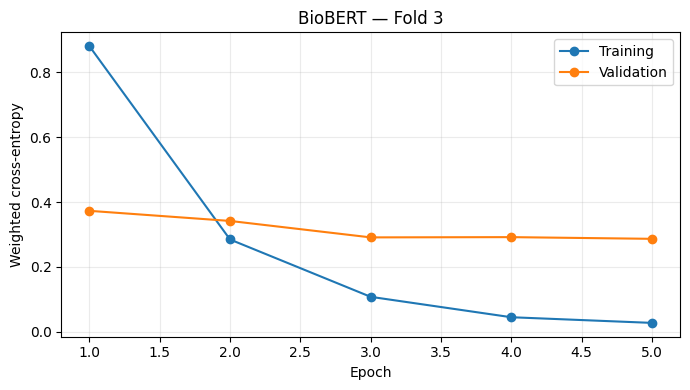


Prediction rows: 612
Saved to: /content/causal_language_reproduction/results/fold_3
MODULE 5M FOLD 3 TRAINING COMPLETED


In [ ]:

# MODULE 5M — FOLD 3 BASELINE TRAINING
# No modifications to Fold 0, 1, or 2 artifacts.

import gc
import json
import hashlib
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from transformers import BertModel, BertTokenizer
from sklearn.metrics import accuracy_score, f1_score, classification_report

ROOT = Path("/content/causal_language_reproduction")
FOLD = 3
OUT = ROOT / "results" / f"fold_{FOLD}"

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

SEED = 0
EPOCHS = 5
TRAIN_BATCH = 32
EVAL_BATCH = 8
MAX_LENGTH = 128
LR = 2e-5

# Check required validated components
for name in [
    "FoldClassifier",
    "HistoricalBertAdam",
    "PubMedDataset",
    "collate_batch"
]:
    assert name in globals(), f"Missing {name}"

# Protect completed experiments against overwrite
assert not OUT.exists() or not any(OUT.iterdir()), (
    f"Existing Fold {FOLD} artifacts found. "
    "Inspect them before rerunning."
)
OUT.mkdir(parents=True, exist_ok=True)

# 1. Load original data and frozen manifest
data_path = (
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv"
)
df = pd.read_csv(
    data_path,
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)
df["sentence"] = df["sentence"].str.strip()

manifest_path = ROOT / "data" / "manifests" / f"fold_{FOLD}.json"
manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)
manifest_hash = hashlib.sha256(manifest_bytes).hexdigest()

assert manifest["fold"] == FOLD
assert len(df) == 3061

fit_ids = manifest["fit_indices"]
val_ids = manifest["validation_indices"]
test_ids = manifest["test_indices"]

assert (len(fit_ids), len(val_ids), len(test_ids)) == (
    2327, 122, 612
)

fit_set, val_set, test_set = (
    set(fit_ids), set(val_ids), set(test_ids)
)
assert fit_set.isdisjoint(val_set)
assert fit_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)
assert len(fit_set | val_set | test_set) == len(df)

# 2. Re-establish seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Free previously loaded models
for name in [
    "model", "restored_model", "base_model",
    "optimizer", "fresh_classifier", "classifier"
]:
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 3. Build tokenizer and DataLoaders
tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

fit_ds = PubMedDataset(df, fit_ids)
val_ds = PubMedDataset(df, val_ids)
test_ds = PubMedDataset(df, test_ids)

train_generator = torch.Generator().manual_seed(SEED)

train_dl = DataLoader(
    fit_ds,
    batch_size=TRAIN_BATCH,
    shuffle=True,
    generator=train_generator,
    num_workers=0,
    collate_fn=collate_batch
)
val_dl = DataLoader(
    val_ds,
    batch_size=EVAL_BATCH,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)
test_dl = DataLoader(
    test_ds,
    batch_size=EVAL_BATCH,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

total_steps = len(train_dl) * EPOCHS
assert len(train_dl) == 73
assert total_steps == 365

# 4. Load a fresh pretrained BioBERT
base_model, loading_info = BertModel.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    use_safetensors=False,
    output_loading_info=True
)

assert not loading_info.get("missing_keys")
assert not loading_info.get("mismatched_keys")
assert not loading_info.get("error_msgs")

model = FoldClassifier(base_model)

# Historical initialization of classification head only
torch.manual_seed(SEED)
with torch.no_grad():
    nn.init.normal_(
        model.classifier.weight,
        mean=0.0,
        std=0.02
    )
    nn.init.zeros_(model.classifier.bias)

model = model.to(device)

# 5. Original weight-decay grouping
no_decay = ["bias", "LayerNorm.bias", "LayerNorm.weight"]
named = list(model.named_parameters())

decay_params = [
    p for n, p in named
    if not any(x in n for x in no_decay)
]
no_decay_params = [
    p for n, p in named
    if any(x in n for x in no_decay)
]

assert len(decay_params) == 77
assert len(no_decay_params) == 124

optimizer = HistoricalBertAdam(
    [
        {"params": decay_params, "weight_decay": 0.01},
        {"params": no_decay_params, "weight_decay": 0.0}
    ],
    lr=LR,
    total_steps=total_steps,
    warmup=0.1
)

# Match official full-corpus class weighting
counts = torch.tensor(
    [1356, 494, 213, 998],
    dtype=torch.float32,
    device=device
)
weights = counts.sum() / (4 * counts)

def inputs_to_device(batch):
    return {
        k: batch[k].to(device)
        for k in [
            "input_ids", "attention_mask", "token_type_ids"
        ]
    }

def evaluate_current_fold(loader, retain_predictions=False):
    model.eval()
    truths, predictions, probabilities, row_ids = [], [], [], []
    total_loss = 0.0

    with torch.inference_mode():
        for batch in loader:
            labels = batch["labels"].to(device)
            logits = model(**inputs_to_device(batch))

            losses = F.cross_entropy(
                logits,
                labels,
                weight=weights,
                reduction="none"
            )

            probs = torch.softmax(logits, dim=-1)

            total_loss += losses.sum().item()
            truths.extend(labels.cpu().tolist())
            predictions.extend(probs.argmax(-1).cpu().tolist())

            if retain_predictions:
                probabilities.extend(probs.cpu().tolist())
                row_ids.extend(batch["row_ids"].tolist())

    result = {
        "loss": total_loss / len(truths),
        "accuracy": accuracy_score(truths, predictions),
        "macro_f1": f1_score(
            truths, predictions,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )
    }

    if retain_predictions:
        result.update({
            "true": truths,
            "pred": predictions,
            "probabilities": probabilities,
            "row_ids": row_ids
        })

    return result

# 6. Train for five epochs
history = []
start_time = time.time()

print("=== FOLD 3 TRAINING ===", flush=True)
print("Device:", device, flush=True)
print(
    "Fit / Val / Test:",
    len(fit_ds), len(val_ds), len(test_ds),
    flush=True
)
print("Optimizer steps:", total_steps, flush=True)

for epoch in range(1, EPOCHS + 1):
    model.train()

    train_loss_sum = 0.0
    train_samples = 0

    for batch_number, batch in enumerate(train_dl):
        optimizer.zero_grad(set_to_none=True)

        labels = batch["labels"].to(device)
        logits = model(**inputs_to_device(batch))

        loss = F.cross_entropy(
            logits,
            labels,
            weight=weights,
            reduction="none"
        ).mean()

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Nonfinite loss: epoch {epoch}, "
                f"batch {batch_number}"
            )

        loss.backward()
        optimizer.step()

        n = len(labels)
        train_loss_sum += loss.item() * n
        train_samples += n

    val = evaluate_current_fold(val_dl)

    record = {
        "epoch": epoch,
        "train_loss": train_loss_sum / train_samples,
        "val_loss": val["loss"],
        "val_accuracy": val["accuracy"],
        "val_macro_f1": val["macro_f1"]
    }
    history.append(record)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss={record['train_loss']:.4f} | "
        f"val loss={record['val_loss']:.4f} | "
        f"val acc={record['val_accuracy']:.4f} | "
        f"val macro-F1={record['val_macro_f1']:.4f}",
        flush=True
    )

# 7. Evaluate only the final-epoch model
test = evaluate_current_fold(
    test_dl,
    retain_predictions=True
)

assert len(test["row_ids"]) == 612
assert len(set(test["row_ids"])) == 612
assert set(test["row_ids"]) == test_set

print("\n=== FOLD 3 HELD-OUT RESULTS ===")
print("Accuracy:", test["accuracy"])
print("Macro-F1:", test["macro_f1"])

print(classification_report(
    test["true"],
    test["pred"],
    labels=[0, 1, 2, 3],
    zero_division=0
))

# 8. Save results
history_df = pd.DataFrame(history)
history_df.to_csv(
    OUT / "training_history.csv",
    index=False
)

pred_df = pd.DataFrame({
    "row_id": test["row_ids"],
    "true_label": test["true"],
    "pred_label": test["pred"]
})

for class_id in range(4):
    pred_df[f"p{class_id}"] = [
        row[class_id] for row in test["probabilities"]
    ]

pred_df.to_csv(
    OUT / "test_predictions.csv",
    index=False
)

metadata = {
    "fold": FOLD,
    "model_id": MODEL_ID,
    "revision": REVISION,
    "manifest_sha256": manifest_hash,
    "epochs": EPOCHS,
    "learning_rate": LR,
    "train_batch_size": TRAIN_BATCH,
    "eval_batch_size": EVAL_BATCH,
    "max_seq_length": MAX_LENGTH,
    "total_optimizer_steps": total_steps,
    "optimizer": "historical_BertAdam_adaptation",
    "seed": SEED,
    "internal_split": "saved_seeded_randperm",
    "num_workers": 0,
    "accuracy": test["accuracy"],
    "macro_f1": test["macro_f1"],
    "seconds_elapsed": time.time() - start_time
}

with open(OUT / "metrics.json", "w") as f:
    json.dump(metadata, f, indent=2)

torch.save(
    model.state_dict(),
    OUT / "final_model_state.pt"
)

plt.figure(figsize=(7, 4))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy")
plt.title("BioBERT — Fold 3")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(
    OUT / "loss_curve.png",
    dpi=150
)
plt.show()

print("\nPrediction rows:", len(pred_df))
print("Saved to:", OUT)
print("MODULE 5M FOLD 3 TRAINING COMPLETED")


In [ ]:

# MODULE 5N: Independent Fold 3 prediction audit
# READ-ONLY: no training or artifact modifications.

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

ROOT = Path("/content/causal_language_reproduction")
FOLD = 3
OUT = ROOT / "results" / f"fold_{FOLD}"

# -----------------------------------------
# 1. Verify required artifacts
# -----------------------------------------
required_files = [
    "training_history.csv",
    "test_predictions.csv",
    "metrics.json",
    "final_model_state.pt",
    "loss_curve.png"
]

print("=== FOLD 3 ARTIFACT AUDIT ===")

for filename in required_files:
    path = OUT / filename
    print(filename, "exists:", path.is_file())
    assert path.is_file(), f"Missing artifact: {path}"

history = pd.read_csv(OUT / "training_history.csv")
pred = pd.read_csv(OUT / "test_predictions.csv")

with open(OUT / "metrics.json") as f:
    metrics = json.load(f)

manifest_path = ROOT / "data/manifests/fold_3.json"
manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)

original = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv",
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)

assert len(original) == 3061
assert manifest["fold"] == metrics["fold"] == 3
assert history["epoch"].tolist() == [1, 2, 3, 4, 5]
assert len(pred) == 612

print("\nHistory rows:", len(history))
print("Prediction rows:", len(pred))

# -----------------------------------------
# 2. Validate row identity and original labels
# -----------------------------------------
required_columns = [
    "row_id", "true_label", "pred_label",
    "p0", "p1", "p2", "p3"
]

assert all(c in pred.columns for c in required_columns)
assert not pred[required_columns].isna().any().any()

row_ids = pred["row_id"].to_numpy(dtype=int)
y_true = pred["true_label"].to_numpy(dtype=int)
y_pred = pred["pred_label"].to_numpy(dtype=int)

assert len(np.unique(row_ids)) == 612
assert set(row_ids) == set(manifest["test_indices"])

gold = original.iloc[row_ids]["label"].to_numpy()
assert np.array_equal(gold, y_true)

assert set(np.unique(y_true)).issubset({0, 1, 2, 3})
assert set(np.unique(y_pred)).issubset({0, 1, 2, 3})

# -----------------------------------------
# 3. Validate all saved probabilities
# -----------------------------------------
probabilities = pred[
    ["p0", "p1", "p2", "p3"]
].to_numpy()

assert probabilities.shape == (612, 4)
assert np.isfinite(probabilities).all()
assert np.all(
    (probabilities >= 0) &
    (probabilities <= 1)
)
assert np.allclose(
    probabilities.sum(axis=1),
    1.0,
    atol=1e-5
)
assert np.array_equal(
    probabilities.argmax(axis=1),
    y_pred
)

# -----------------------------------------
# 4. Independently recompute test metrics
# -----------------------------------------
accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    average="macro",
    zero_division=0
)

correct = int(np.sum(y_true == y_pred))
incorrect = int(np.sum(y_true != y_pred))

print("\n=== INDEPENDENT FOLD 3 METRICS ===")
print("Accuracy:", accuracy)
print("Macro-F1:", macro_f1)
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)

assert np.isclose(
    accuracy,
    0.8905228758169934,
    atol=1e-12
)
assert np.isclose(
    macro_f1,
    0.8714718817767598,
    atol=1e-12
)

assert np.isclose(
    accuracy, metrics["accuracy"], atol=1e-12
)
assert np.isclose(
    macro_f1, metrics["macro_f1"], atol=1e-12
)

assert correct == 545
assert incorrect == 67

# -----------------------------------------
# 5. Confusion matrix
# -----------------------------------------
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

print("\nConfusion matrix:")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    zero_division=0
))

assert cm.shape == (4, 4)
assert cm.sum() == 612
assert np.trace(cm) == 545

# -----------------------------------------
# 6. Verify configuration and manifest
# -----------------------------------------
manifest_hash = hashlib.sha256(
    manifest_bytes
).hexdigest()

assert metrics["manifest_sha256"] == manifest_hash
assert metrics["epochs"] == 5
assert metrics["total_optimizer_steps"] == 365
assert metrics["train_batch_size"] == 32
assert metrics["eval_batch_size"] == 8
assert metrics["max_seq_length"] == 128

checkpoint = OUT / "final_model_state.pt"
assert checkpoint.stat().st_size > 0

print("\n=== ARTIFACT INTEGRITY ===")
print("Checkpoint bytes:", checkpoint.stat().st_size)
print("Manifest SHA-256:", manifest_hash)

print("\nRow alignment: PASSED")
print("Original gold labels: PASSED")
print("Probability normalization: PASSED")
print("Prediction argmax: PASSED")
print("Independent metrics: PASSED")
print("Manifest fingerprint: PASSED")

print("\nMODULE 5N FOLD 3 PREDICTION AUDIT PASSED")


=== FOLD 3 ARTIFACT AUDIT ===
training_history.csv exists: True
test_predictions.csv exists: True
metrics.json exists: True
final_model_state.pt exists: True
loss_curve.png exists: True

History rows: 5
Prediction rows: 612

=== INDEPENDENT FOLD 3 METRICS ===
Accuracy: 0.8905228758169934
Macro-F1: 0.8714718817767598
Correct predictions: 545
Incorrect predictions: 67

Confusion matrix:
[[240  10   4  17]
 [  6  87   6   0]
 [  3   2  36   1]
 [ 13   5   0 182]]

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.89      0.90       271
           1       0.84      0.88      0.86        99
           2       0.78      0.86      0.82        42
           3       0.91      0.91      0.91       200

    accuracy                           0.89       612
   macro avg       0.86      0.88      0.87       612
weighted avg       0.89      0.89      0.89       612


=== ARTIFACT INTEGRITY ===
Checkpoint bytes: 433337475
Manifest SHA-256: 31

In [ ]:

# MODULE 5O: Fold 3 full checkpoint restoration audit

from pathlib import Path
import gc
import json
import numpy as np
import pandas as pd
import torch

from transformers import BertConfig, BertModel, BertTokenizer
from torch.utils.data import DataLoader

ROOT = Path("/content/causal_language_reproduction")
FOLD = 3
OUT = ROOT / "results" / f"fold_{FOLD}"

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

for name in ["FoldClassifier", "PubMedDataset", "collate_batch"]:
    assert name in globals(), f"Missing definition: {name}"

# 1. Load saved results and manifest
saved = pd.read_csv(OUT / "test_predictions.csv")

with open(ROOT / "data/manifests/fold_3.json") as f:
    fold_manifest = json.load(f)

assert fold_manifest["fold"] == FOLD
assert len(saved) == 612
assert saved["row_id"].is_unique
assert set(saved["row_id"]) == set(
    fold_manifest["test_indices"]
)

original = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv",
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)
original["sentence"] = original["sentence"].str.strip()

# 2. Release previous models
for name in [
    "model", "base_model", "optimizer",
    "restored_model", "fresh_classifier", "classifier"
]:
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 3. Reconstruct architecture without loading pretrained weights
config = BertConfig.from_pretrained(
    MODEL_ID,
    revision=REVISION
)

restored_model = FoldClassifier(BertModel(config))

# Restore every trained parameter
state = torch.load(
    OUT / "final_model_state.pt",
    map_location="cpu",
    weights_only=True
)

load_info = restored_model.load_state_dict(
    state,
    strict=True
)

del state
gc.collect()

assert not load_info.missing_keys
assert not load_info.unexpected_keys

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

restored_model = restored_model.to(device)
restored_model.eval()

# collate_batch uses this tokenizer
tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

# 4. Preserve the saved prediction order
ordered_ids = saved["row_id"].astype(int).tolist()

audit_dataset = PubMedDataset(
    original,
    ordered_ids
)

audit_loader = DataLoader(
    audit_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

# 5. Reproduce all test predictions
restored_ids = []
restored_labels = []
restored_probabilities = []

with torch.inference_mode():
    for batch in audit_loader:
        inputs = {
            k: batch[k].to(device)
            for k in [
                "input_ids",
                "attention_mask",
                "token_type_ids"
            ]
        }

        logits = restored_model(**inputs)
        probabilities = torch.softmax(
            logits,
            dim=-1
        )

        restored_ids.extend(
            batch["row_ids"].tolist()
        )

        restored_labels.extend(
            probabilities.argmax(dim=-1).cpu().tolist()
        )

        restored_probabilities.extend(
            probabilities.cpu().tolist()
        )

# 6. Compare against the saved predictions
restored_probabilities = np.asarray(
    restored_probabilities
)

saved_probabilities = saved[
    ["p0", "p1", "p2", "p3"]
].to_numpy()

restored_labels = np.asarray(restored_labels)
saved_labels = saved["pred_label"].to_numpy()

assert restored_ids == ordered_ids
assert restored_probabilities.shape == (612, 4)
assert np.isfinite(restored_probabilities).all()

max_difference = float(
    np.max(
        np.abs(
            restored_probabilities - saved_probabilities
        )
    )
)

mismatched_labels = int(
    np.sum(restored_labels != saved_labels)
)

print("=== FOLD 3 CHECKPOINT RESTORATION ===")
print("Device:", device)
print("Missing keys:", load_info.missing_keys)
print("Unexpected keys:", load_info.unexpected_keys)
print("Rows independently evaluated:", len(restored_ids))
print("Mismatched predicted labels:", mismatched_labels)
print("Maximum probability difference:", max_difference)

assert mismatched_labels == 0

assert np.allclose(
    restored_probabilities,
    saved_probabilities,
    rtol=1e-4,
    atol=1e-5
), "Restored probabilities differ from saved predictions."

print("\nCheckpoint restored successfully: True")
print("All 612 predictions reproduced: True")
print("Probability comparison: PASSED")
print("\nMODULE 5O FOLD 3 CHECKPOINT AUDIT PASSED")


=== FOLD 3 CHECKPOINT RESTORATION ===
Device: cuda
Missing keys: []
Unexpected keys: []
Rows independently evaluated: 612
Mismatched predicted labels: 0
Maximum probability difference: 5.245208740234375e-06

Checkpoint restored successfully: True
All 612 predictions reproduced: True
Probability comparison: PASSED

MODULE 5O FOLD 3 CHECKPOINT AUDIT PASSED


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


=== FOLD 4 TRAINING ===
Device: cuda
Fit / Val / Test: 2327 122 612
Steps per epoch: 73
Total optimizer steps: 365
Epoch 1/5 | train loss=0.8733 | val loss=0.5004 | val acc=0.8033 | val macro-F1=0.7783
Epoch 2/5 | train loss=0.2991 | val loss=0.3755 | val acc=0.8607 | val macro-F1=0.8334
Epoch 3/5 | train loss=0.0924 | val loss=0.3984 | val acc=0.8525 | val macro-F1=0.8372
Epoch 4/5 | train loss=0.0408 | val loss=0.4489 | val acc=0.8770 | val macro-F1=0.8591
Epoch 5/5 | train loss=0.0190 | val loss=0.4631 | val acc=0.8770 | val macro-F1=0.8591

=== FOLD 4 HELD-OUT RESULTS ===
Accuracy: 0.9084967320261438
Macro-F1: 0.8902258100956071
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       271
           1       0.87      0.86      0.86        99
           2       0.82      0.88      0.85        42
           3       0.92      0.94      0.93       200

    accuracy                           0.91       612
   macro avg       0.88      0.90

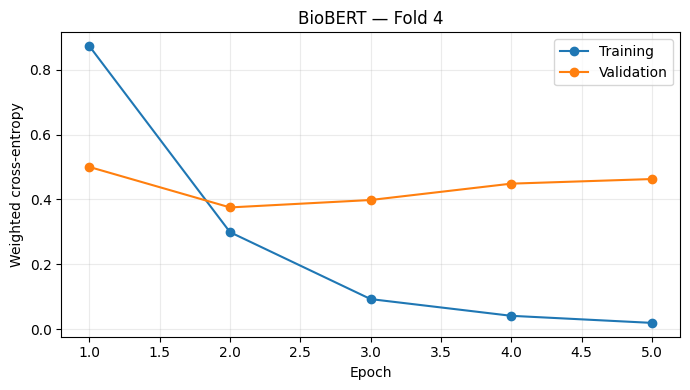


Prediction rows: 612
Saved to: /content/causal_language_reproduction/results/fold_4
Manifest SHA-256: 9f62bad4f11a2b68dc6b7bdf343ccec194d06cfd861a8f4ae086d23153c2183e
MODULE 5P FOLD 4 TRAINING COMPLETED


In [ ]:

# MODULE 5P: Train and evaluate Fold 4
# Final fold of the frozen five-fold baseline protocol.

from pathlib import Path
import gc
import json
import hashlib
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from transformers import BertModel, BertTokenizer
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)

ROOT = Path("/content/causal_language_reproduction")
FOLD = 4
OUT = ROOT / "results" / "fold_4"

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

SEED = 0
EPOCHS = 5
TRAIN_BATCH = 32
EVAL_BATCH = 8
LR = 2e-5
MAX_LENGTH = 128

# -------------------------------------------
# 0. Validate dependencies and output safety
# -------------------------------------------

for name in [
    "FoldClassifier",
    "HistoricalBertAdam",
    "PubMedDataset",
    "collate_batch"
]:
    assert name in globals(), f"Missing: {name}"

assert not OUT.exists() or not any(OUT.iterdir()), (
    "Fold 4 output directory already contains files. "
    "Inspect existing artifacts before rerunning."
)

OUT.mkdir(parents=True, exist_ok=True)

# -------------------------------------------
# 1. Load dataset and saved Fold 4 manifest
# -------------------------------------------

DATA_FILE = (
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv"
)

df = pd.read_csv(
    DATA_FILE,
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)

df["sentence"] = df["sentence"].str.strip()

manifest_path = ROOT / "data/manifests/fold_4.json"
manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)

manifest_hash = hashlib.sha256(
    manifest_bytes
).hexdigest()

assert len(df) == 3061
assert manifest["fold"] == FOLD

fit_ids = manifest["fit_indices"]
val_ids = manifest["validation_indices"]
test_ids = manifest["test_indices"]

assert (
    len(fit_ids),
    len(val_ids),
    len(test_ids)
) == (2327, 122, 612)

fit_set = set(fit_ids)
val_set = set(val_ids)
test_set = set(test_ids)

assert fit_set.isdisjoint(val_set)
assert fit_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)
assert len(fit_set | val_set | test_set) == 3061

# -------------------------------------------
# 2. Reset random seeds and release old models
# -------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

for name in [
    "model", "base_model", "restored_model",
    "optimizer", "fresh_classifier", "classifier",
    "encoder"
]:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# -------------------------------------------
# 3. Tokenizer and DataLoaders
# -------------------------------------------

# collate_batch uses the global variable tokenizer
tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

fit_ds = PubMedDataset(df, fit_ids)
val_ds = PubMedDataset(df, val_ids)
test_ds = PubMedDataset(df, test_ids)

train_generator = torch.Generator().manual_seed(SEED)

train_dl = DataLoader(
    fit_ds,
    batch_size=TRAIN_BATCH,
    shuffle=True,
    generator=train_generator,
    num_workers=0,
    collate_fn=collate_batch
)

val_dl = DataLoader(
    val_ds,
    batch_size=EVAL_BATCH,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

test_dl = DataLoader(
    test_ds,
    batch_size=EVAL_BATCH,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

steps_per_epoch = len(train_dl)
total_steps = steps_per_epoch * EPOCHS

assert steps_per_epoch == 73
assert total_steps == 365

# -------------------------------------------
# 4. Load fresh pretrained BioBERT
# -------------------------------------------

base_model, loading_info = BertModel.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    use_safetensors=False,
    output_loading_info=True
)

assert not loading_info.get("missing_keys")
assert not loading_info.get("mismatched_keys")
assert not loading_info.get("error_msgs")

model = FoldClassifier(base_model)

# Historical classifier-head initialization
torch.manual_seed(SEED)

with torch.no_grad():
    nn.init.normal_(
        model.classifier.weight,
        mean=0.0,
        std=0.02
    )
    nn.init.zeros_(model.classifier.bias)

model = model.to(device)

# -------------------------------------------
# 5. Historical-style BertAdam optimizer
# -------------------------------------------

no_decay = [
    "bias",
    "LayerNorm.bias",
    "LayerNorm.weight"
]

named_params = list(model.named_parameters())

decay_params = [
    p for name, p in named_params
    if not any(x in name for x in no_decay)
]

no_decay_params = [
    p for name, p in named_params
    if any(x in name for x in no_decay)
]

assert len(decay_params) == 77
assert len(no_decay_params) == 124

optimizer = HistoricalBertAdam(
    [
        {
            "params": decay_params,
            "weight_decay": 0.01
        },
        {
            "params": no_decay_params,
            "weight_decay": 0.0
        }
    ],
    lr=LR,
    total_steps=total_steps,
    warmup=0.1
)

# Retain the original paper's full-corpus
# class-weight calculation.
counts = torch.tensor(
    [1356, 494, 213, 998],
    dtype=torch.float32,
    device=device
)

weights = counts.sum() / (4 * counts)

def to_device(batch):
    return {
        key: batch[key].to(device)
        for key in [
            "input_ids",
            "attention_mask",
            "token_type_ids"
        ]
    }

# -------------------------------------------
# 6. Evaluation function
# -------------------------------------------

def evaluate_fold4(loader, retain_predictions=False):
    model.eval()

    gold = []
    predictions = []
    probabilities = []
    row_ids = []

    loss_sum = 0.0

    with torch.inference_mode():
        for batch in loader:
            labels = batch["labels"].to(device)
            logits = model(**to_device(batch))

            losses = F.cross_entropy(
                logits,
                labels,
                weight=weights,
                reduction="none"
            )

            probs = torch.softmax(logits, dim=-1)

            loss_sum += losses.sum().item()

            gold.extend(labels.cpu().tolist())
            predictions.extend(
                probs.argmax(dim=-1).cpu().tolist()
            )

            if retain_predictions:
                probabilities.extend(
                    probs.cpu().tolist()
                )
                row_ids.extend(
                    batch["row_ids"].tolist()
                )

    result = {
        "loss": loss_sum / len(gold),
        "accuracy": accuracy_score(gold, predictions),
        "macro_f1": f1_score(
            gold,
            predictions,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )
    }

    if retain_predictions:
        result.update({
            "gold": gold,
            "predictions": predictions,
            "probabilities": probabilities,
            "row_ids": row_ids
        })

    return result

# -------------------------------------------
# 7. Train for exactly five epochs
# -------------------------------------------

history = []
start_time = time.time()

print("=== FOLD 4 TRAINING ===", flush=True)
print("Device:", device, flush=True)
print(
    "Fit / Val / Test:",
    len(fit_ds), len(val_ds), len(test_ds),
    flush=True
)
print("Steps per epoch:", steps_per_epoch, flush=True)
print("Total optimizer steps:", total_steps, flush=True)

for epoch in range(1, EPOCHS + 1):
    model.train()

    train_loss_sum = 0.0
    train_samples = 0

    for batch_number, batch in enumerate(train_dl):
        optimizer.zero_grad(set_to_none=True)

        labels = batch["labels"].to(device)
        logits = model(**to_device(batch))

        loss = F.cross_entropy(
            logits,
            labels,
            weight=weights,
            reduction="none"
        ).mean()

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Nonfinite loss at epoch={epoch}, "
                f"batch={batch_number}"
            )

        loss.backward()
        optimizer.step()

        n = len(labels)
        train_loss_sum += loss.item() * n
        train_samples += n

    validation = evaluate_fold4(val_dl)

    record = {
        "epoch": epoch,
        "train_loss": train_loss_sum / train_samples,
        "val_loss": validation["loss"],
        "val_accuracy": validation["accuracy"],
        "val_macro_f1": validation["macro_f1"]
    }

    history.append(record)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss={record['train_loss']:.4f} | "
        f"val loss={record['val_loss']:.4f} | "
        f"val acc={record['val_accuracy']:.4f} | "
        f"val macro-F1={record['val_macro_f1']:.4f}",
        flush=True
    )

# -------------------------------------------
# 8. Held-out final-epoch evaluation
# -------------------------------------------

test = evaluate_fold4(
    test_dl,
    retain_predictions=True
)

assert len(test["row_ids"]) == 612
assert len(set(test["row_ids"])) == 612
assert set(test["row_ids"]) == test_set

print("\n=== FOLD 4 HELD-OUT RESULTS ===")
print("Accuracy:", test["accuracy"])
print("Macro-F1:", test["macro_f1"])

print(classification_report(
    test["gold"],
    test["predictions"],
    labels=[0, 1, 2, 3],
    zero_division=0
))

# -------------------------------------------
# 9. Save evaluation artifacts
# -------------------------------------------

history_df = pd.DataFrame(history)
history_df.to_csv(
    OUT / "training_history.csv",
    index=False
)

pred_df = pd.DataFrame({
    "row_id": test["row_ids"],
    "true_label": test["gold"],
    "pred_label": test["predictions"]
})

for class_id in range(4):
    pred_df[f"p{class_id}"] = [
        row[class_id]
        for row in test["probabilities"]
    ]

pred_df.to_csv(
    OUT / "test_predictions.csv",
    index=False
)

metadata = {
    "fold": FOLD,
    "model_id": MODEL_ID,
    "revision": REVISION,
    "manifest_sha256": manifest_hash,
    "epochs": EPOCHS,
    "learning_rate": LR,
    "train_batch_size": TRAIN_BATCH,
    "eval_batch_size": EVAL_BATCH,
    "max_seq_length": MAX_LENGTH,
    "total_optimizer_steps": total_steps,
    "optimizer": "historical_BertAdam_adaptation",
    "seed": SEED,
    "internal_split": "saved_seeded_randperm",
    "num_workers": 0,
    "accuracy": test["accuracy"],
    "macro_f1": test["macro_f1"],
    "seconds_elapsed": time.time() - start_time
}

with open(OUT / "metrics.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Final epoch, not the best validation epoch.
torch.save(
    model.state_dict(),
    OUT / "final_model_state.pt"
)

plt.figure(figsize=(7, 4))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy")
plt.title("BioBERT — Fold 4")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / "loss_curve.png", dpi=150)
plt.show()

print("\nPrediction rows:", len(pred_df))
print("Saved to:", OUT)
print("Manifest SHA-256:", manifest_hash)
print("MODULE 5P FOLD 4 TRAINING COMPLETED")


In [ ]:

# MODULE 5Q: Independent Fold 4 artifact and prediction audit
# READ-ONLY — no training or saved-file modifications.

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

ROOT = Path("/content/causal_language_reproduction")
FOLD = 4
OUT = ROOT / "results" / "fold_4"

# ----------------------------------------
# 1. Verify required artifacts
# ----------------------------------------

required_files = [
    "training_history.csv",
    "test_predictions.csv",
    "metrics.json",
    "final_model_state.pt",
    "loss_curve.png"
]

print("=== FOLD 4 ARTIFACT AUDIT ===")

for filename in required_files:
    path = OUT / filename
    print(filename, "exists:", path.is_file())
    assert path.is_file(), f"Missing: {path}"

history = pd.read_csv(OUT / "training_history.csv")
pred = pd.read_csv(OUT / "test_predictions.csv")

with open(OUT / "metrics.json") as f:
    metrics = json.load(f)

manifest_path = ROOT / "data/manifests/fold_4.json"
manifest_bytes = manifest_path.read_bytes()
manifest = json.loads(manifest_bytes)

original = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv",
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)

assert len(original) == 3061
assert manifest["fold"] == metrics["fold"] == FOLD
assert len(history) == 5
assert history["epoch"].tolist() == [1, 2, 3, 4, 5]
assert len(pred) == 612

print("\nHistory rows:", len(history))
print("Prediction rows:", len(pred))

# ----------------------------------------
# 2. Validate row identities and labels
# ----------------------------------------

required_columns = [
    "row_id", "true_label", "pred_label",
    "p0", "p1", "p2", "p3"
]

assert all(c in pred.columns for c in required_columns)
assert not pred[required_columns].isna().any().any()

row_ids = pred["row_id"].to_numpy(dtype=int)
y_true = pred["true_label"].to_numpy(dtype=int)
y_pred = pred["pred_label"].to_numpy(dtype=int)

assert len(np.unique(row_ids)) == 612
assert set(row_ids) == set(manifest["test_indices"])

original_labels = original.iloc[row_ids]["label"].to_numpy()
assert np.array_equal(original_labels, y_true)

assert set(np.unique(y_true)).issubset({0, 1, 2, 3})
assert set(np.unique(y_pred)).issubset({0, 1, 2, 3})

# ----------------------------------------
# 3. Validate saved probabilities
# ----------------------------------------

probabilities = pred[
    ["p0", "p1", "p2", "p3"]
].to_numpy(dtype=float)

assert probabilities.shape == (612, 4)
assert np.isfinite(probabilities).all()
assert np.all(
    (probabilities >= 0.0) &
    (probabilities <= 1.0)
)
assert np.allclose(
    probabilities.sum(axis=1),
    1.0,
    atol=1e-5
)
assert np.array_equal(
    probabilities.argmax(axis=1),
    y_pred
)

# ----------------------------------------
# 4. Recompute metrics independently
# ----------------------------------------

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    average="macro",
    zero_division=0
)

correct = int((y_true == y_pred).sum())
incorrect = int((y_true != y_pred).sum())

print("\n=== INDEPENDENT FOLD 4 METRICS ===")
print("Accuracy:", accuracy)
print("Macro-F1:", macro_f1)
print("Correct:", correct)
print("Incorrect:", incorrect)

assert np.isclose(
    accuracy,
    0.9084967320261438,
    atol=1e-12
)
assert np.isclose(
    macro_f1,
    0.8902258100956071,
    atol=1e-12
)

assert np.isclose(
    accuracy,
    metrics["accuracy"],
    atol=1e-12
)
assert np.isclose(
    macro_f1,
    metrics["macro_f1"],
    atol=1e-12
)

assert correct == 556
assert incorrect == 56

# ----------------------------------------
# 5. Confusion matrix
# ----------------------------------------

cm = confusion_matrix(
    y_true, y_pred,
    labels=[0, 1, 2, 3]
)

print("\nConfusion matrix:")
print(cm)

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3],
    zero_division=0
))

assert cm.shape == (4, 4)
assert cm.sum() == 612
assert np.trace(cm) == 556

# ----------------------------------------
# 6. Check manifest and run configuration
# ----------------------------------------

manifest_hash = hashlib.sha256(
    manifest_bytes
).hexdigest()

expected_hash = (
    "9f62bad4f11a2b68dc6b7bdf343ccec"
    "194d06cfd861a8f4ae086d23153c2183e"
)

assert manifest_hash == expected_hash
assert metrics["manifest_sha256"] == manifest_hash
assert metrics["epochs"] == 5
assert metrics["total_optimizer_steps"] == 365
assert metrics["train_batch_size"] == 32
assert metrics["eval_batch_size"] == 8
assert metrics["max_seq_length"] == 128
assert metrics["optimizer"] == "historical_BertAdam_adaptation"

checkpoint = OUT / "final_model_state.pt"
checkpoint_bytes = checkpoint.stat().st_size
assert checkpoint_bytes > 0

print("\n=== ARTIFACT INTEGRITY ===")
print("Checkpoint bytes:", checkpoint_bytes)
print("Manifest SHA-256:", manifest_hash)

print("\nOriginal row alignment: PASSED")
print("Gold labels: PASSED")
print("Probability normalization: PASSED")
print("Prediction argmax agreement: PASSED")
print("Independent metrics: PASSED")
print("Manifest integrity: PASSED")

print("\nMODULE 5Q FOLD 4 PREDICTION AUDIT PASSED")


=== FOLD 4 ARTIFACT AUDIT ===
training_history.csv exists: True
test_predictions.csv exists: True
metrics.json exists: True
final_model_state.pt exists: True
loss_curve.png exists: True

History rows: 5
Prediction rows: 612

=== INDEPENDENT FOLD 4 METRICS ===
Accuracy: 0.9084967320261438
Macro-F1: 0.8902258100956071
Correct: 556
Incorrect: 56

Confusion matrix:
[[247   8   3  13]
 [  6  85   4   4]
 [  4   1  37   0]
 [  8   4   1 187]]

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       271
           1       0.87      0.86      0.86        99
           2       0.82      0.88      0.85        42
           3       0.92      0.94      0.93       200

    accuracy                           0.91       612
   macro avg       0.88      0.90      0.89       612
weighted avg       0.91      0.91      0.91       612


=== ARTIFACT INTEGRITY ===
Checkpoint bytes: 433337475
Manifest SHA-256: 9f62bad4f11a2b68dc6b7bdf34

In [ ]:

# MODULE 5R: Fold 4 checkpoint restoration audit
# READ-ONLY: no training or modification to saved artifacts.

from pathlib import Path
import gc
import json
import numpy as np
import pandas as pd
import torch

from transformers import BertConfig, BertModel, BertTokenizer
from torch.utils.data import DataLoader

ROOT = Path("/content/causal_language_reproduction")
FOLD = 4
OUT = ROOT / "results" / "fold_4"

MODEL_ID = "dmis-lab/biobert-base-cased-v1.1"
REVISION = "924f12e0c3db7f156a765ad53fb6b11e7afedbc8"

# 1. Verify previously defined classes
for name in ["FoldClassifier", "PubMedDataset", "collate_batch"]:
    assert name in globals(), f"Missing definition: {name}"

# 2. Load predictions and frozen fold indices
saved = pd.read_csv(OUT / "test_predictions.csv")

with open(ROOT / "data/manifests/fold_4.json") as f:
    fold_manifest = json.load(f)

assert fold_manifest["fold"] == FOLD
assert len(saved) == 612
assert saved["row_id"].is_unique
assert set(saved["row_id"]) == set(
    fold_manifest["test_indices"]
)

original = pd.read_csv(
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv",
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)
original["sentence"] = original["sentence"].str.strip()

# 3. Release previous models to reduce GPU memory usage
for name in [
    "model", "base_model", "restored_model",
    "optimizer", "fresh_classifier", "classifier", "encoder"
]:
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 4. Reconstruct architecture without loading pretrained weights
config = BertConfig.from_pretrained(
    MODEL_ID,
    revision=REVISION
)

restored_model = FoldClassifier(BertModel(config))

# Load final-epoch trained parameters
state = torch.load(
    OUT / "final_model_state.pt",
    map_location="cpu",
    weights_only=True
)

load_info = restored_model.load_state_dict(
    state,
    strict=True
)

del state
gc.collect()

assert not load_info.missing_keys
assert not load_info.unexpected_keys

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

restored_model = restored_model.to(device)
restored_model.eval()

# 5. Restore the same case-sensitive tokenizer
# collate_batch uses the global variable 'tokenizer'
tokenizer = BertTokenizer.from_pretrained(
    MODEL_ID,
    revision=REVISION,
    do_lower_case=False
)

# Preserve exact saved prediction order
ordered_ids = saved["row_id"].astype(int).tolist()

audit_dataset = PubMedDataset(original, ordered_ids)

audit_loader = DataLoader(
    audit_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_batch
)

# 6. Independently reproduce all held-out predictions
restored_ids = []
restored_labels = []
restored_probabilities = []

with torch.inference_mode():
    for batch in audit_loader:
        inputs = {
            k: batch[k].to(device)
            for k in [
                "input_ids",
                "attention_mask",
                "token_type_ids"
            ]
        }

        logits = restored_model(**inputs)
        probs = torch.softmax(logits, dim=-1)

        restored_ids.extend(batch["row_ids"].tolist())
        restored_labels.extend(
            probs.argmax(dim=-1).cpu().tolist()
        )
        restored_probabilities.extend(
            probs.cpu().tolist()
        )

# 7. Compare restored and saved outputs
restored_probabilities = np.asarray(
    restored_probabilities
)

saved_probabilities = saved[
    ["p0", "p1", "p2", "p3"]
].to_numpy(dtype=float)

restored_labels = np.asarray(restored_labels)
saved_labels = saved["pred_label"].to_numpy()

assert restored_ids == ordered_ids
assert restored_probabilities.shape == (612, 4)
assert np.isfinite(restored_probabilities).all()

max_difference = float(
    np.abs(
        restored_probabilities - saved_probabilities
    ).max()
)

mismatched_labels = int(
    np.sum(restored_labels != saved_labels)
)

print("=== FOLD 4 CHECKPOINT RESTORATION ===")
print("Device:", device)
print("Missing keys:", load_info.missing_keys)
print("Unexpected keys:", load_info.unexpected_keys)
print("Rows independently evaluated:", len(restored_ids))
print("Mismatched predicted labels:", mismatched_labels)
print("Maximum probability difference:", max_difference)

assert mismatched_labels == 0

assert np.allclose(
    restored_probabilities,
    saved_probabilities,
    rtol=1e-4,
    atol=1e-5
), "Restored probabilities differ from saved predictions."

print("\nCheckpoint restored successfully: True")
print("All 612 predictions reproduced: True")
print("Probability comparison: PASSED")
print("\nMODULE 5R FOLD 4 CHECKPOINT AUDIT PASSED")


=== FOLD 4 CHECKPOINT RESTORATION ===
Device: cuda
Missing keys: []
Unexpected keys: []
Rows independently evaluated: 612
Mismatched predicted labels: 0
Maximum probability difference: 2.3245811462402344e-06

Checkpoint restored successfully: True
All 612 predictions reproduced: True
Probability comparison: PASSED

MODULE 5R FOLD 4 CHECKPOINT AUDIT PASSED


In [ ]:

# MODULE 5S: Final five-fold baseline validation
# Read-only. No training, model loading, or artifact changes.

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

ROOT = Path("/content/causal_language_reproduction")
RESULTS = ROOT / "results"
MANIFESTS = ROOT / "data" / "manifests"
DATA = (
    ROOT / "causal-language-use-in-science"
    / "data/pubmed_causal_language_use.csv"
)

original = pd.read_csv(
    DATA,
    usecols=["sentence", "label"],
    encoding="utf8",
    keep_default_na=False
)

original["sentence"] = original["sentence"].str.strip()

N = len(original)
assert N == 3061

fold_metrics = []
prediction_frames = []
all_manifest_test_ids = []

print("=== FIVE-FOLD INDEPENDENT VALIDATION ===")

for fold in range(5):
    out = RESULTS / f"fold_{fold}"

    # 1. Read actual saved artifacts
    pred = pd.read_csv(out / "test_predictions.csv")
    history = pd.read_csv(out / "training_history.csv")

    with open(out / "metrics.json") as f:
        saved_metrics = json.load(f)

    manifest_bytes = (
        MANIFESTS / f"fold_{fold}.json"
    ).read_bytes()

    manifest = json.loads(manifest_bytes)
    manifest_hash = hashlib.sha256(
        manifest_bytes
    ).hexdigest()

    # 2. Validate record counts and training protocol
    expected_size = 613 if fold == 0 else 612

    assert len(pred) == expected_size
    assert history["epoch"].tolist() == [1, 2, 3, 4, 5]
    assert manifest["fold"] == fold
    assert saved_metrics["fold"] == fold

    assert saved_metrics["epochs"] == 5
    assert saved_metrics["max_seq_length"] == 128
    assert saved_metrics["optimizer"] == (
        "historical_BertAdam_adaptation"
    )

    # Fold 0 metadata uses a slightly different
    # naming convention from Folds 1-4.
    saved_hash = saved_metrics.get(
        "manifest_sha256",
        saved_metrics.get("dataset_manifest_sha256")
    )
    assert saved_hash == manifest_hash

    # 3. Verify fit/validation/test disjointness
    fit_ids = set(manifest["fit_indices"])
    val_ids = set(manifest["validation_indices"])
    test_ids = set(manifest["test_indices"])

    assert fit_ids.isdisjoint(val_ids)
    assert fit_ids.isdisjoint(test_ids)
    assert val_ids.isdisjoint(test_ids)
    assert len(fit_ids | val_ids | test_ids) == N

    # 4. Verify prediction identity
    required = [
        "row_id", "true_label", "pred_label",
        "p0", "p1", "p2", "p3"
    ]

    assert all(col in pred.columns for col in required)
    assert not pred[required].isna().any().any()

    row_ids = pred["row_id"].to_numpy(dtype=int)
    y_true = pred["true_label"].to_numpy(dtype=int)
    y_pred = pred["pred_label"].to_numpy(dtype=int)

    assert len(set(row_ids)) == expected_size
    assert set(row_ids) == test_ids

    original_gold = original.iloc[
        row_ids
    ]["label"].to_numpy()

    assert np.array_equal(y_true, original_gold)

    # 5. Validate probability vectors
    probabilities = pred[
        ["p0", "p1", "p2", "p3"]
    ].to_numpy(dtype=float)

    assert probabilities.shape == (expected_size, 4)
    assert np.isfinite(probabilities).all()
    assert np.all(
        (probabilities >= 0) &
        (probabilities <= 1)
    )

    assert np.allclose(
        probabilities.sum(axis=1),
        1.0, atol=1e-5
    )

    assert np.array_equal(
        probabilities.argmax(axis=1),
        y_pred
    )

    # 6. Independently calculate fold metrics
    acc = accuracy_score(y_true, y_pred)

    macro = f1_score(
        y_true, y_pred,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )

    assert np.isclose(
        acc, saved_metrics["accuracy"], atol=1e-12
    )
    assert np.isclose(
        macro, saved_metrics["macro_f1"], atol=1e-12
    )

    assert (out / "final_model_state.pt").is_file()
    assert (out / "final_model_state.pt").stat().st_size > 0

    fold_metrics.append({
        "fold": fold,
        "test_size": expected_size,
        "accuracy": acc,
        "macro_f1": macro,
        "correct": int((y_true == y_pred).sum())
    })

    pred = pred.copy()
    pred["fold"] = fold
    prediction_frames.append(pred)

    all_manifest_test_ids.extend(
        manifest["test_indices"]
    )

    print(
        f"Fold {fold}: n={expected_size}, "
        f"accuracy={acc:.6f}, macro-F1={macro:.6f} "
        "— PASSED"
    )

# 7. Global coverage: every original row exactly once
assert len(all_manifest_test_ids) == N
assert set(all_manifest_test_ids) == set(range(N))
assert len(set(all_manifest_test_ids)) == N

pooled = pd.concat(
    prediction_frames, ignore_index=True
)

assert len(pooled) == N
assert pooled["row_id"].is_unique
assert set(pooled["row_id"]) == set(range(N))

# Sort for independent full-dataset label comparison
pooled = pooled.sort_values("row_id").reset_index(drop=True)

assert np.array_equal(
    pooled["true_label"].to_numpy(),
    original["label"].to_numpy()
)

# 8. Five-fold arithmetic means and sample SD
summary = pd.DataFrame(fold_metrics)

mean_accuracy = summary["accuracy"].mean()
mean_macro_f1 = summary["macro_f1"].mean()

sd_accuracy = summary["accuracy"].std(ddof=1)
sd_macro_f1 = summary["macro_f1"].std(ddof=1)

# 9. Pooled out-of-fold metrics
pooled_accuracy = accuracy_score(
    pooled["true_label"],
    pooled["pred_label"]
)

pooled_macro_f1 = f1_score(
    pooled["true_label"],
    pooled["pred_label"],
    labels=[0, 1, 2, 3],
    average="macro",
    zero_division=0
)

correct_total = int(
    (pooled["true_label"] == pooled["pred_label"]).sum()
)

cm = confusion_matrix(
    pooled["true_label"],
    pooled["pred_label"],
    labels=[0, 1, 2, 3]
)

assert cm.sum() == N
assert np.trace(cm) == correct_total

print("\n=== FINAL FIVE-FOLD RESULTS ===")
print(summary.to_string(index=False))

print("\nMean fold accuracy:", mean_accuracy)
print("Sample SD accuracy:", sd_accuracy)
print("Mean fold macro-F1:", mean_macro_f1)
print("Sample SD macro-F1:", sd_macro_f1)

print("\n=== POOLED OUT-OF-FOLD RESULTS ===")
print("Total evaluated:", len(pooled))
print("Correct:", correct_total)
print("Incorrect:", N - correct_total)
print("Pooled accuracy:", pooled_accuracy)
print("Pooled macro-F1:", pooled_macro_f1)

print("\nPooled confusion matrix:")
print(cm)

print("\nPooled classification report:")
print(classification_report(
    pooled["true_label"],
    pooled["pred_label"],
    labels=[0, 1, 2, 3],
    zero_division=0
))

# 10. Reference comparison (not a replication assertion)
PAPER_ACC = 0.900
PAPER_MACRO_F1 = 0.883

print("\n=== PUBLISHED REFERENCE COMPARISON ===")
print("Published mean accuracy:", PAPER_ACC)
print("Our mean accuracy:", mean_accuracy)
print("Difference:", mean_accuracy - PAPER_ACC)

print("Published mean macro-F1:", PAPER_MACRO_F1)
print("Our mean macro-F1:", mean_macro_f1)
print("Difference:", mean_macro_f1 - PAPER_MACRO_F1)

print("\n=== GLOBAL VALIDATION ===")
print("Every original row evaluated exactly once: PASSED")
print("All five fold metrics independently reproduced: PASSED")
print("All manifests match saved metadata: PASSED")
print("All probability vectors validated: PASSED")
print("All five checkpoints exist: PASSED")

print("\nMODULE 5S FIVE-FOLD AGGREGATION PASSED")


=== FIVE-FOLD INDEPENDENT VALIDATION ===
Fold 0: n=613, accuracy=0.890701, macro-F1=0.878400 — PASSED
Fold 1: n=612, accuracy=0.900327, macro-F1=0.887420 — PASSED
Fold 2: n=612, accuracy=0.900327, macro-F1=0.883495 — PASSED
Fold 3: n=612, accuracy=0.890523, macro-F1=0.871472 — PASSED
Fold 4: n=612, accuracy=0.908497, macro-F1=0.890226 — PASSED

=== FINAL FIVE-FOLD RESULTS ===
 fold  test_size  accuracy  macro_f1  correct
    0        613  0.890701  0.878400      546
    1        612  0.900327  0.887420      551
    2        612  0.900327  0.883495      551
    3        612  0.890523  0.871472      545
    4        612  0.908497  0.890226      556

Mean fold accuracy: 0.8980749341607226
Sample SD accuracy: 0.007585466900178226
Mean fold macro-F1: 0.8822025345457721
Sample SD macro-F1: 0.007464542238939849

=== POOLED OUT-OF-FOLD RESULTS ===
Total evaluated: 3061
Correct: 2749
Incorrect: 312
Pooled accuracy: 0.8980725253185233
Pooled macro-F1: 0.8821695585710827

Pooled confusion matrix: